# ACCESO A DATOS DEL MINISTERIO DE TRABAJO

(ejecutar en el entorno "venv")

---

+ Para acceder a diferentes estadísticas sobre el Mercado Laboral español se puede consultar esta página:
    + https://expinterweb.mites.gob.es/series/
+ Accederemos a los datos del mercado de trabajo temporal:
    + Bajo "Empresas de Trabajo Temporal"
    + En la nueva pantalla que aparece elegiremos:
        + Paso 1:
            + Como "Variable de análisis": "EMPRESAS DE TRABAJO TEMPORAL".
            + Como "Variables de clasificación": "Divisiones de actividad".
        + Paso 2:
            + Seleccione los valores de las variables de clasificación:
                + Cada sector de actividad de España está normalizado por un nombre "CNAE".
                + Selecionamos todos los sectores.
        + Paso 3:
            + Seleccione los valores de la variable temporal:
                + Año: Todos los años disponibles
                + PERIODICIDAD: MENSUAL: Todos los meses
        + Paso 4:
            + Seleccione el formato de salida de los datos
                + La salida será un fichero que lo bajamos como "Excel" 
                + Se descarga automáticamente con un nombre aleatorio.

![Alt text](datos/Captura%20de%20pantalla%202023-03-20%20a%20las%2021.25.24.png)

+ El fichero tiene una estructura un tanto irregular.
+ Por esta estrcutura no he encontrado manera de poder leerle con _pandas_ o con _openpyxl_.
+ Pruebo a leerle con *R*.
    + En *R* existen diferentes librerías para leer ficheros de Excel que están muy optimizadas (C++). 

![Alt text](datos/Captura%20de%20pantalla%202023-04-11%20a%20las%2021.15.14.png)

In [32]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [33]:
%%R

suppressPackageStartupMessages({
  library(data.table)
  library(ggplot2)
  library(tictoc)
  library(stringr)
  library(janitor)
  library(ggeasy)
  library(stringi)
  library(forcats)
  library(lubridate)
  library(tidytable)
  library(SheetReader)
  library(broom)
})


tic()
# ------------  File In
# Skip 4 first rows with the title of the report.
direxcel <- './datos/'
fileexcl <- 'Trabajo_Temporal_CNAEs_2018_2022.xlsx'
dirfile  <- paste0(direxcel, fileexcl)

datin <- read_xlsx(dirfile, skip_rows = 4)
names(datin)[1:2] <- c('ano', 'mes')

#To fill Anios...
for (i in 1:nrow(datin)) {
  # print(i)
   if ( !is.na(datin$ano[i]) & !is.na(datin$mes[i]) ) { 
        year_tmp <- datin$ano[i]
     } 
   if ( is.na(datin$ano[i]) & !is.na(datin$mes[i]) ) {
       datin$ano[i] <- year_tmp
     } else {next}
}

datindt <- as.data.table(datin)
# Remove last rows invalid
datingd <- datindt[ !is.na(ano) & !(str_detect(ano, "Datos provisionales")), ]
datingd$ano <- as.numeric(datingd$ano)

# Change "mes" values to numeric
datingd[ , mesnum := fcase(
  mes == "Enero", 1,
  mes == "Febrero", 2,
  mes == "Marzo", 3,
  mes == "Abril", 4,
  mes == "Mayo", 5,
  mes == "Junio", 6,
  mes == "Julio", 7,
  mes == "Agosto", 8,
  mes == "Septiembre", 9,
  mes == "Octubre", 10,
  mes == "Noviembre", 11, 
  mes == "Diciembre", 12
)
]
datingd[ , yearmon := (ano * 100 + mesnum) ]
datingd[ , yearmondat := ym(yearmon) ]

# reorder columns - first - ano - mes - mesnum - yearmon - yearmondat
datingd <- datingd[, c(1:2, 93:95, 3:92)]

# Melt everything excel 5 first columns...
# datingdlg <- melt(datingd, id.vars = c(1:5))
#- Save file processed.
fwrite(datingd, file = "./datos/Datos_Raw_CNAES_.csv", bom = TRUE)

toc()




0.13 sec elapsed


----

In [34]:
import pandas as pd

datosmt = pd.read_csv("./datos/Datos_Raw_CNAEs_.csv")
datosmt.head()


,ano,mes,mesnum,yearmon,yearmondat,TOTAL,"01. Agricultura, ganadería, caza y servicios relacionados con las mismas",02. Silvicultura y explotación forestal,03. Pesca y acuicultura,"05. Extracción de antracita, hulla y lignito",...,"91. Actividades de bibliotecas, archivos, museos y otras actividades culturales",92. Actividades de juegos de azar y apuestas,"93. Actividades deportivas, recreativas y de entretenimiento",94. Actividades asociativas,"95. Reparación de ordenadores, efectos personales y artículos de uso doméstico",96. Otros servicios personales,97. Actividades de los hogares como empleadores de personal doméstico,98. Actividades de los hogares como productores de bienes y servicios para uso propio,99. Actividades de organizaciones y organismos extraterritoriales,NC. No Clasificables
,<int64>,<object>,<int64>,<int64>,<object>,<int64>,<int64>,<int64>,<int64>,<int64>,...,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>
0,2009,Enero,1,200901,2009-01-01,128947,17880,8,63,2,...,111,269,1453,560,147,361,33,0,5,142
1,2009,Febrero,2,200902,2009-02-01,100722,12999,1,32,0,...,188,285,1027,489,106,290,11,0,5,71
2,2009,Marzo,3,200903,2009-03-01,111494,10533,9,60,1,...,4,82,1451,652,84,359,26,0,2,84
3,2009,Abril,4,200904,2009-04-01,120636,15965,0,72,0,...,126,559,1404,530,76,268,20,0,6,99
4,2009,Mayo,5,200905,2009-05-01,139572,19964,0,77,0,...,256,398,2224,650,81,368,23,0,7,78


In [35]:
datosmt.columns

Index(['ano', 'mes', 'mesnum', 'yearmon', 'yearmondat', 'TOTAL',
       '01. Agricultura, ganadería, caza y servicios relacionados con las mismas',
       '02. Silvicultura y explotación forestal', '03. Pesca y acuicultura',
       '05. Extracción de antracita, hulla y lignito',
       '06. Extracción de crudo de petróleo y gas natural',
       '07. Extracción de minerales metálicos',
       '08. Otras industrias extractivas',
       '09. Actividades de apoyo a las industrias extractivas',
       '10. Industria de la alimentación', '11. Fabricación de bebidas',
       '12. Industria del tabaco', '13. Industria textil',
       '14. Confección de prendas de vestir',
       '15. Industria del cuero y del calzado',
       '16. Industria de la madera y del corcho, excepto muebles; cestería y espartería',
       '17. Industria del papel',
       '18. Artes gráficas y reproducción de soportes grabados',
       '19. Coquerías y refino de petróleo', '20. Industria química',
       '21. Fabricac

+ Los nombres de las columnas son bastante "poco amigables", hay que evitar este tipo de nombres en lo posible.
+ El paquete "pyjanitor" (equivalente a "janitor" en R) permite corregir este problema con una de sus funciones "clean_names()".
    + Aplicamos esa función para corregir los nombres antes de pivotar.

In [36]:
import janitor

datosmtcl = datosmt.clean_names(remove_special = True)
datosmtcl.head()


,ano,mes,mesnum,yearmon,yearmondat,total,01_agricultura_ganaderia_caza_y_servicios_relacionados_con_las_mismas,02_silvicultura_y_explotacion_forestal,03_pesca_y_acuicultura,05_extraccion_de_antracita_hulla_y_lignito,...,91_actividades_de_bibliotecas_archivos_museos_y_otras_actividades_culturales,92_actividades_de_juegos_de_azar_y_apuestas,93_actividades_deportivas_recreativas_y_de_entretenimiento,94_actividades_asociativas,95_reparacion_de_ordenadores_efectos_personales_y_articulos_de_uso_domestico,96_otros_servicios_personales,97_actividades_de_los_hogares_como_empleadores_de_personal_domestico,98_actividades_de_los_hogares_como_productores_de_bienes_y_servicios_para_uso_propio,99_actividades_de_organizaciones_y_organismos_extraterritoriales,nc_no_clasificables
,<int64>,<object>,<int64>,<int64>,<object>,<int64>,<int64>,<int64>,<int64>,<int64>,...,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>,<int64>
0,2009,Enero,1,200901,2009-01-01,128947,17880,8,63,2,...,111,269,1453,560,147,361,33,0,5,142
1,2009,Febrero,2,200902,2009-02-01,100722,12999,1,32,0,...,188,285,1027,489,106,290,11,0,5,71
2,2009,Marzo,3,200903,2009-03-01,111494,10533,9,60,1,...,4,82,1451,652,84,359,26,0,2,84
3,2009,Abril,4,200904,2009-04-01,120636,15965,0,72,0,...,126,559,1404,530,76,268,20,0,6,99
4,2009,Mayo,5,200905,2009-05-01,139572,19964,0,77,0,...,256,398,2224,650,81,368,23,0,7,78


In [37]:
datosmtcl.columns

Index(['ano', 'mes', 'mesnum', 'yearmon', 'yearmondat', 'total',
       '01_agricultura_ganaderia_caza_y_servicios_relacionados_con_las_mismas',
       '02_silvicultura_y_explotacion_forestal', '03_pesca_y_acuicultura',
       '05_extraccion_de_antracita_hulla_y_lignito',
       '06_extraccion_de_crudo_de_petroleo_y_gas_natural',
       '07_extraccion_de_minerales_metalicos',
       '08_otras_industrias_extractivas',
       '09_actividades_de_apoyo_a_las_industrias_extractivas',
       '10_industria_de_la_alimentacion', '11_fabricacion_de_bebidas',
       '12_industria_del_tabaco', '13_industria_textil',
       '14_confeccion_de_prendas_de_vestir',
       '15_industria_del_cuero_y_del_calzado',
       '16_industria_de_la_madera_y_del_corcho_excepto_muebles_cesteria_y_esparteria',
       '17_industria_del_papel',
       '18_artes_graficas_y_reproduccion_de_soportes_grabados',
       '19_coquerias_y_refino_de_petroleo', '20_industria_quimica',
       '21_fabricacion_de_productos_farmaceu

+ Esta estructura de fichero no es un fichero "tidy".
+ Salvo las 5 columnas iniciales, el resto las queremos convertir en una única columna que contenga los diferentes CNAEs y su valor en otra columna.
    + Esto es hacer un "reshape" del conjunto.
    + De esta forma luego es más fácil analizar cada uno de los tipos de CNAESs

In [38]:
type(datosmtcl)

pandas.core.frame.DataFrame

In [39]:
from datar import options
options(import_names_conflict="silent")

from datar import f
from datar.dplyr import mutate, filter, if_else
from datar.tibble import tibble
from datar.base import *
from datar.all import *

In [40]:

datosmtlg = (
    datosmtcl 
    >> pivot_longer(
    cols = f[f.total:f.nc_no_clasificables],
    names_to="tipo",
    values_to="count"
    )
    # nc_no_clasificables no se pivota ??. Lo elimino
    >> select(~f.nc_no_clasificables)
)
datosmtlg

,ano,mes,mesnum,yearmon,yearmondat,tipo,count
,<int64>,<object>,<int64>,<int64>,<object>,<object>,<int64>
0,2009,Enero,1,200901,2009-01-01,total,128947
1,2009,Febrero,2,200902,2009-02-01,total,100722
2,2009,Marzo,3,200903,2009-03-01,total,111494
3,2009,Abril,4,200904,2009-04-01,total,120636
...,...,...,...,...,...,...,...
4,2009,Mayo,5,200905,2009-05-01,total,139572
14947,2022,Agosto,8,202208,2022-08-01,99_actividades_de_organizaciones_y_organismos_...,5
14948,2022,Septiembre,9,202209,2022-09-01,99_actividades_de_organizaciones_y_organismos_...,7
14949,2022,Octubre,10,202210,2022-10-01,99_actividades_de_organizaciones_y_organismos_...,5


+ Ahora lo que haremos es seleccionar cada uno delos "tipo" y pintar la evolución teniendo en cuenta los valores de "count".
+ La evolución la plantearemos con "yearmon".

In [41]:
tipos_val = (
    datosmtlg
    >> select(f.tipo)
    >> distinct()
    >> pull(f.tipo)
)
tipos_val

0                                                    total
168      01_agricultura_ganaderia_caza_y_servicios_rela...
336                 02_silvicultura_y_explotacion_forestal
504                                 03_pesca_y_acuicultura
672             05_extraccion_de_antracita_hulla_y_lignito
                               ...                        
14112    95_reparacion_de_ordenadores_efectos_personale...
14280                        96_otros_servicios_personales
14448    97_actividades_de_los_hogares_como_empleadores...
14616    98_actividades_de_los_hogares_como_productores...
14784    99_actividades_de_organizaciones_y_organismos_...
Name: tipo, Length: 89, dtype: object

+ Tenemos que resetear el índice para poder iterarles correctamente.

In [42]:
tipos_val = tipos_val.reset_index(drop = True)
tipos_val

0                                                 total
1     01_agricultura_ganaderia_caza_y_servicios_rela...
2                02_silvicultura_y_explotacion_forestal
3                                03_pesca_y_acuicultura
4            05_extraccion_de_antracita_hulla_y_lignito
                            ...                        
84    95_reparacion_de_ordenadores_efectos_personale...
85                        96_otros_servicios_personales
86    97_actividades_de_los_hogares_como_empleadores...
87    98_actividades_de_los_hogares_como_productores...
88    99_actividades_de_organizaciones_y_organismos_...
Name: tipo, Length: 89, dtype: object

---

+ Vamos a ver qué resultado obtendríamos con un caso en particular.

In [43]:
i = 0
gr_gr = (
    datosmtlg
    >> filter(f.tipo == tipos_val[i])
    >> mutate(yearmoncat = as_factor(f.yearmon))
    >> arrange(f.yearmon)
)
gr_gr

,ano,mes,mesnum,yearmon,yearmondat,tipo,count,yearmoncat
,<int64>,<object>,<int64>,<int64>,<object>,<object>,<int64>,<category>
0,2009,Enero,1,200901,2009-01-01,total,128947,200901
1,2009,Febrero,2,200902,2009-02-01,total,100722,200902
2,2009,Marzo,3,200903,2009-03-01,total,111494,200903
3,2009,Abril,4,200904,2009-04-01,total,120636,200904
...,...,...,...,...,...,...,...,...
4,2009,Mayo,5,200905,2009-05-01,total,139572,200905
163,2022,Agosto,8,202208,2022-08-01,total,265594,202208
164,2022,Septiembre,9,202209,2022-09-01,total,293269,202209
165,2022,Octubre,10,202210,2022-10-01,total,323403,202210


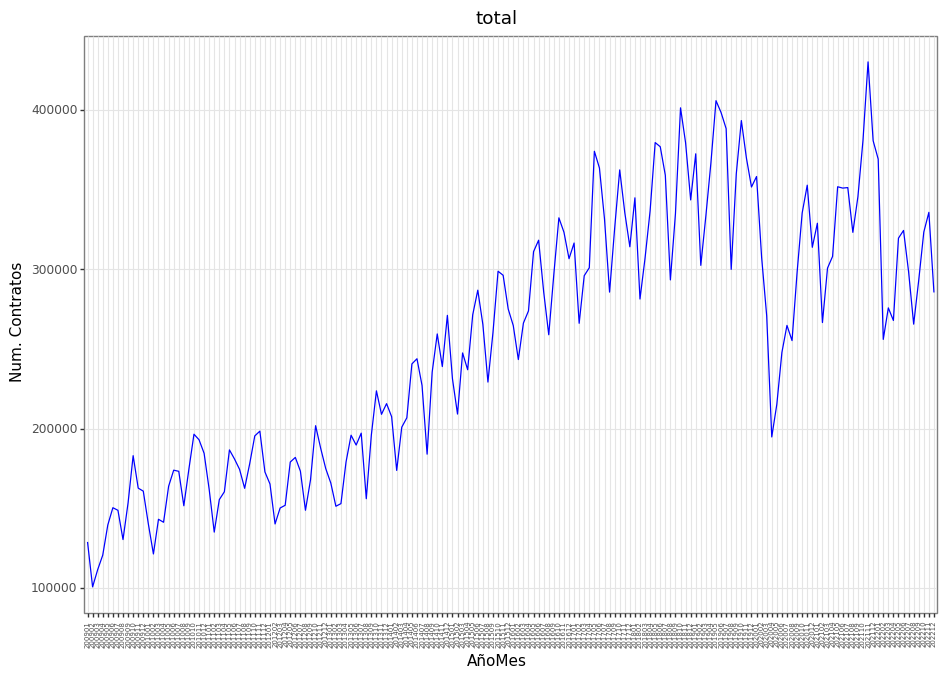

<ggplot: (326483273)>

In [45]:
import plotnine
plotnine.options.figure_size=(11, 7.5)

from plotnine import *


p1 = (
      ggplot(gr_gr, aes(x = "yearmoncat", y = "count"))
    + geom_line(group = 1, color ="blue")
    + labs(
     title = tipos_val[i],
     x = "AñoMes",
     y = "Num. Contratos"
    )
    + theme_bw()
    + theme(
        panel_grid_minor=element_blank(),
        axis_text_x=element_text(angle = 90, hjust = 0.5, size = 5)
    )
)
p1

---

+ Y ahora ejecutamos con un bucle para todos los tipos.

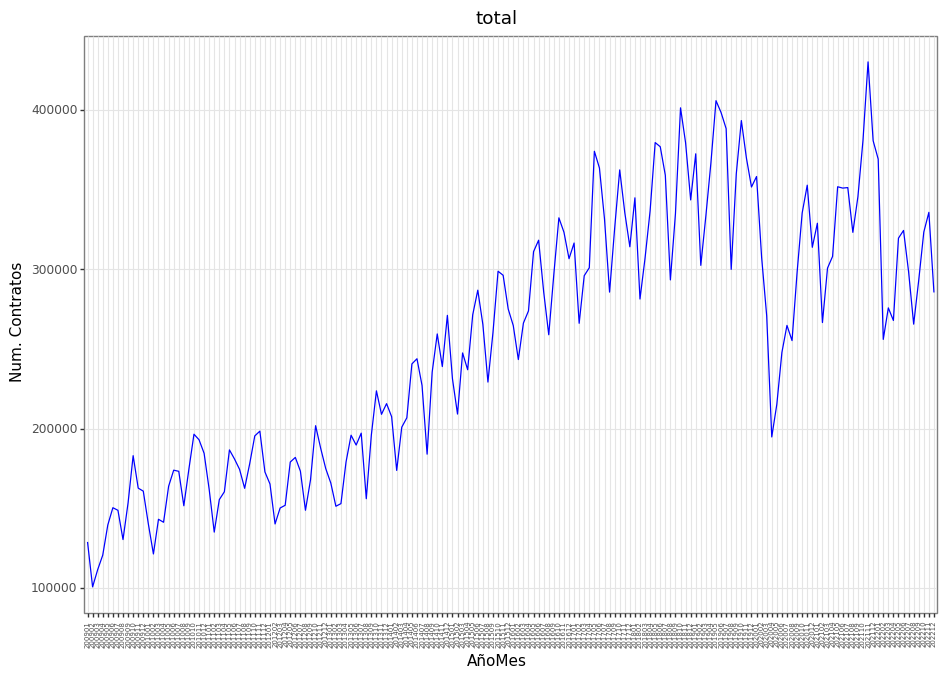

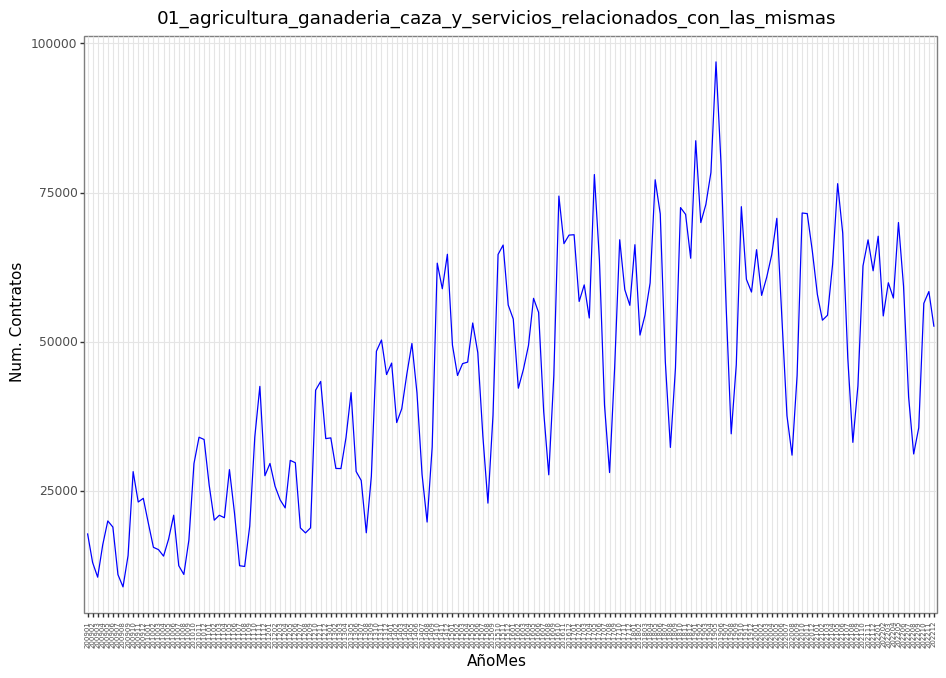

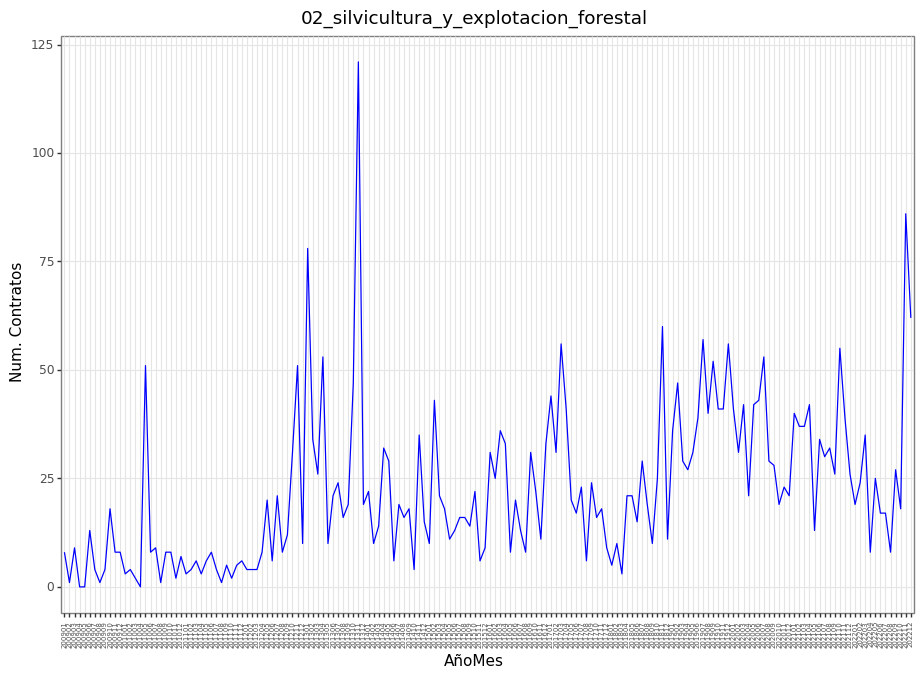

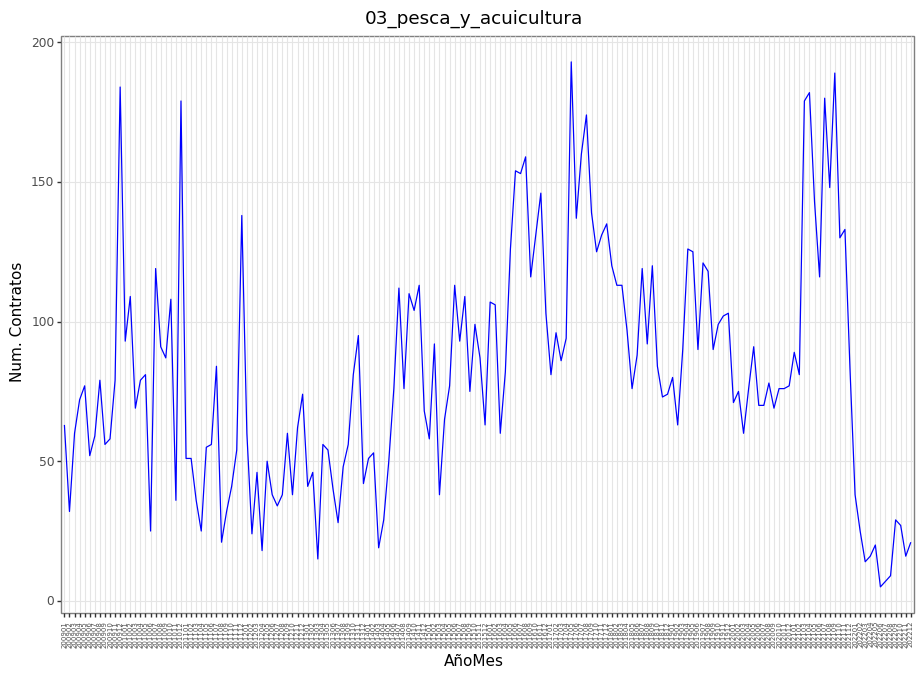

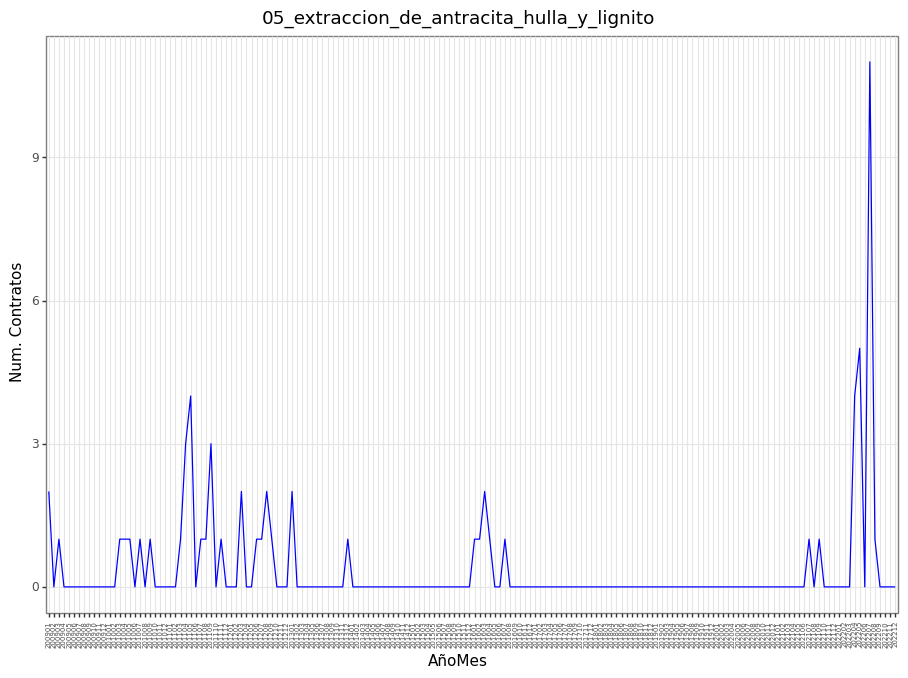

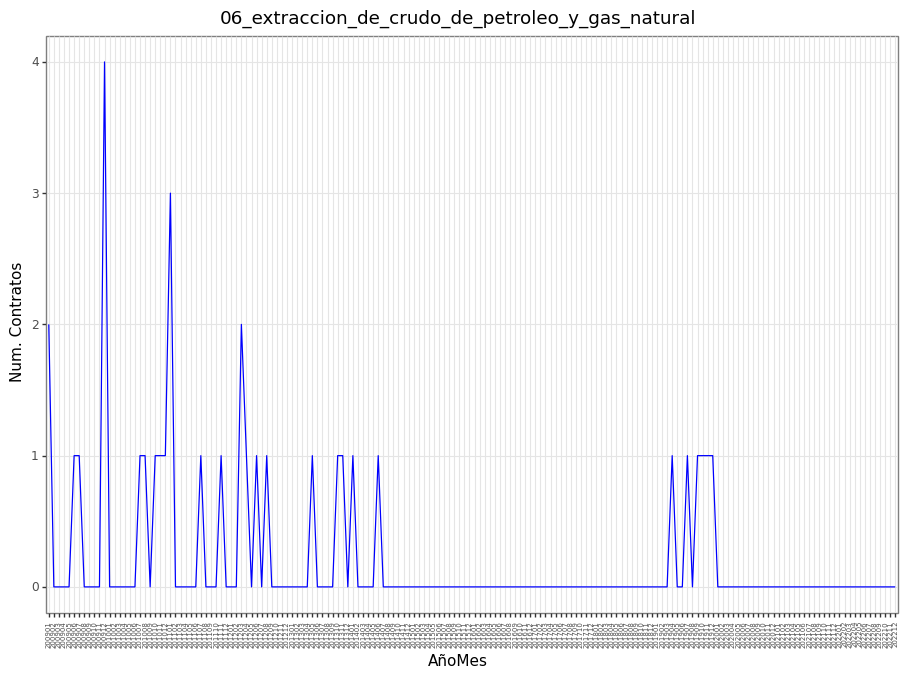

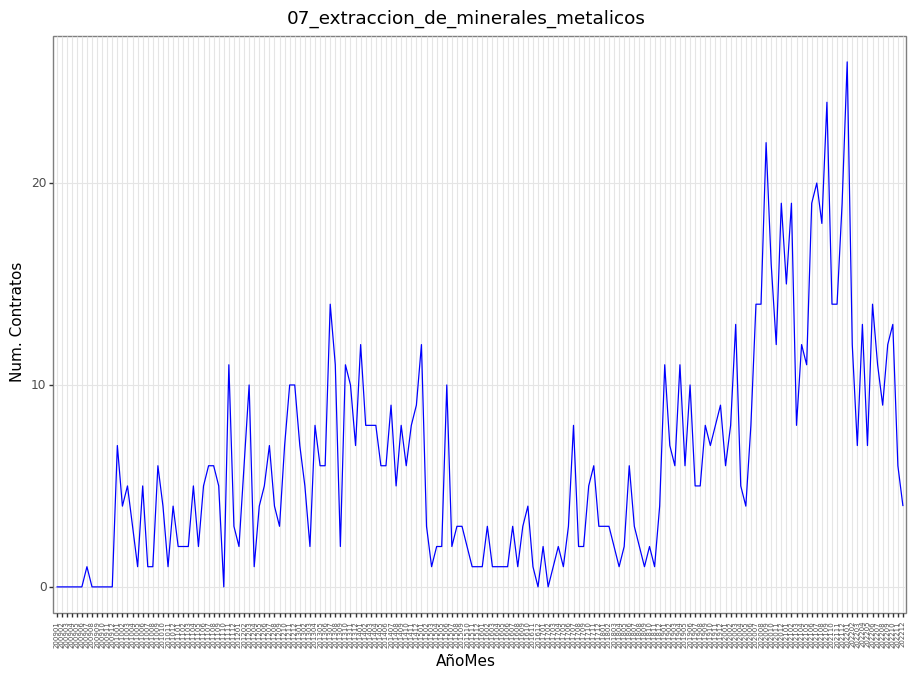

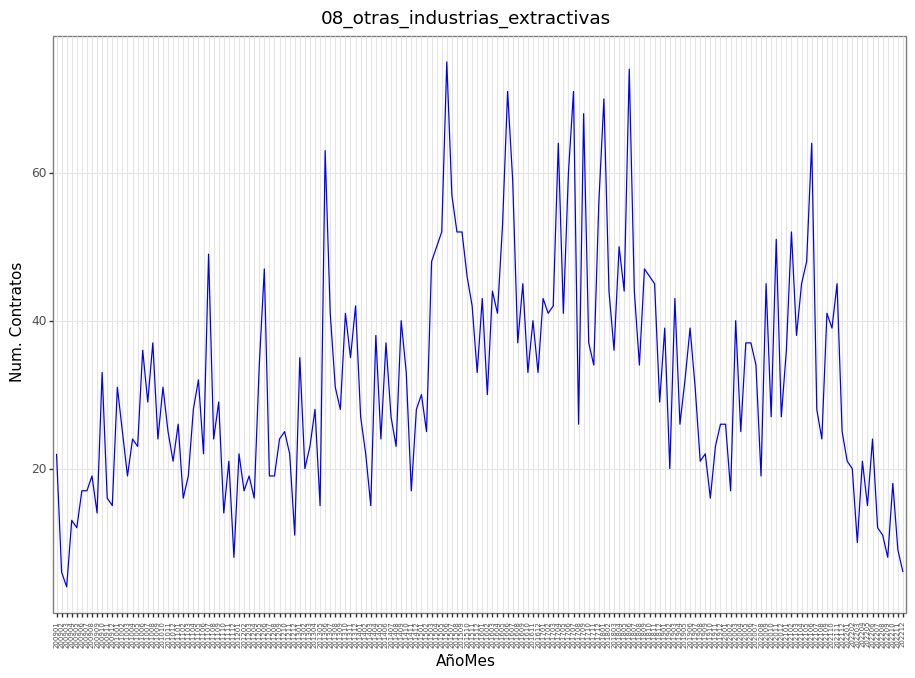

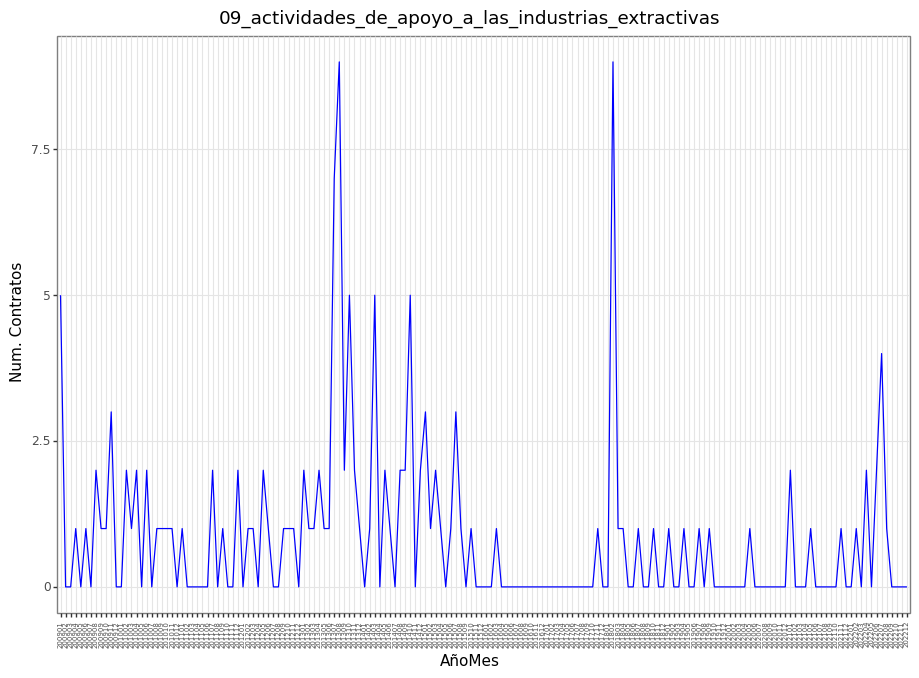

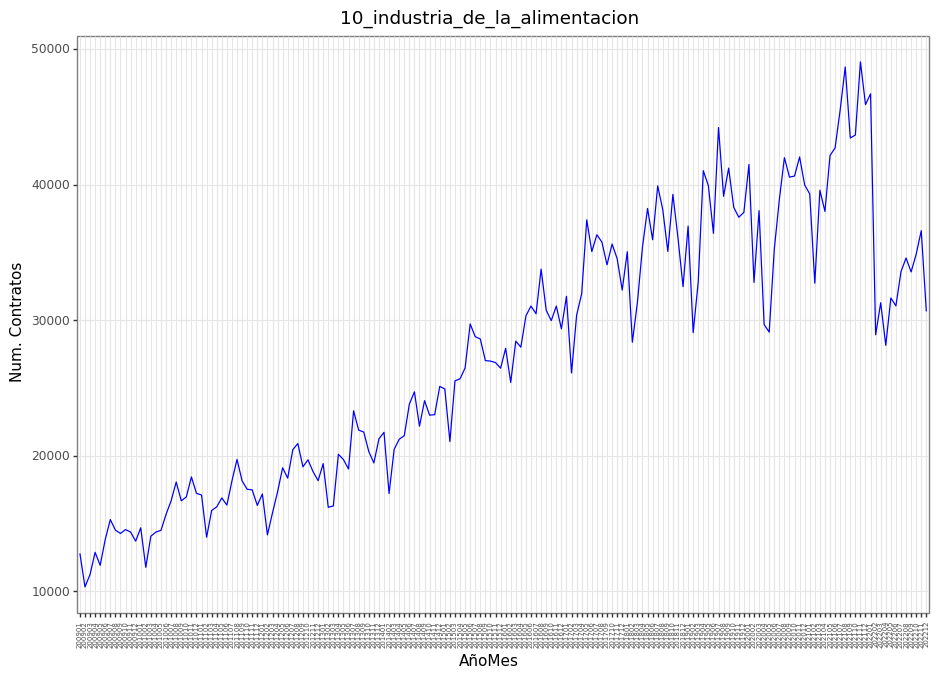

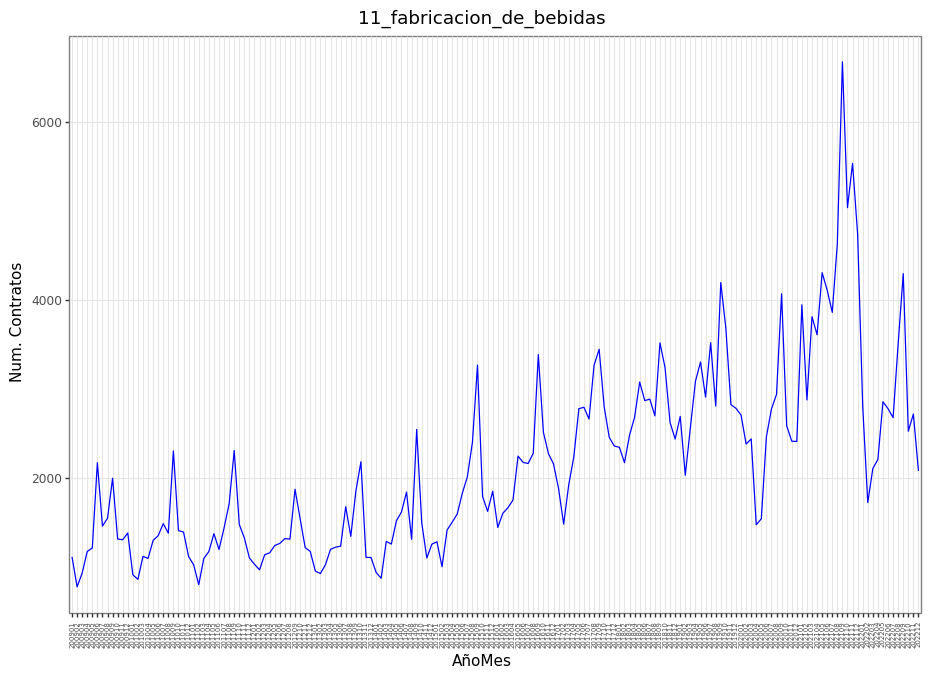

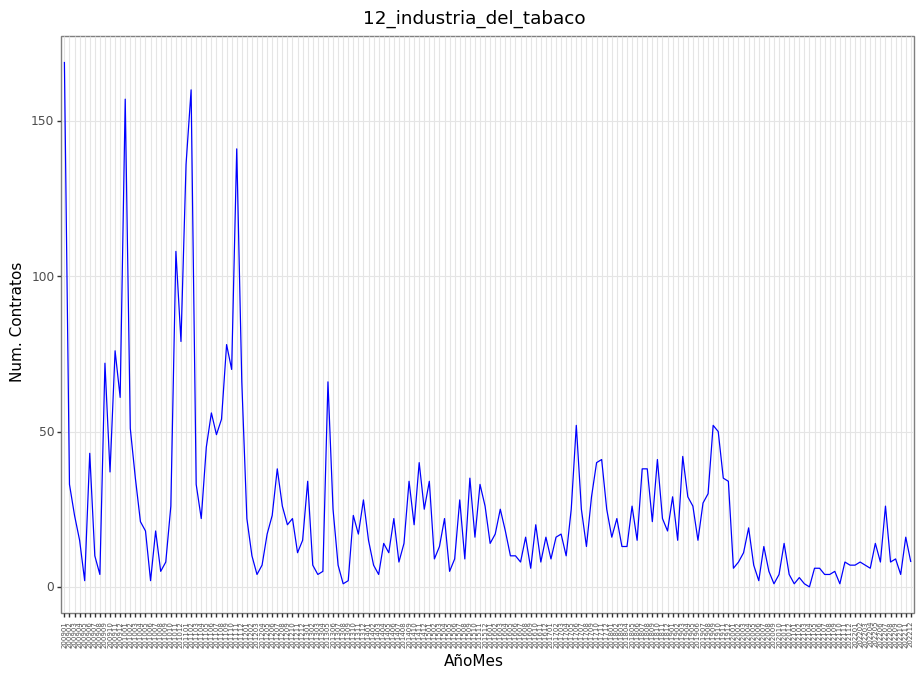

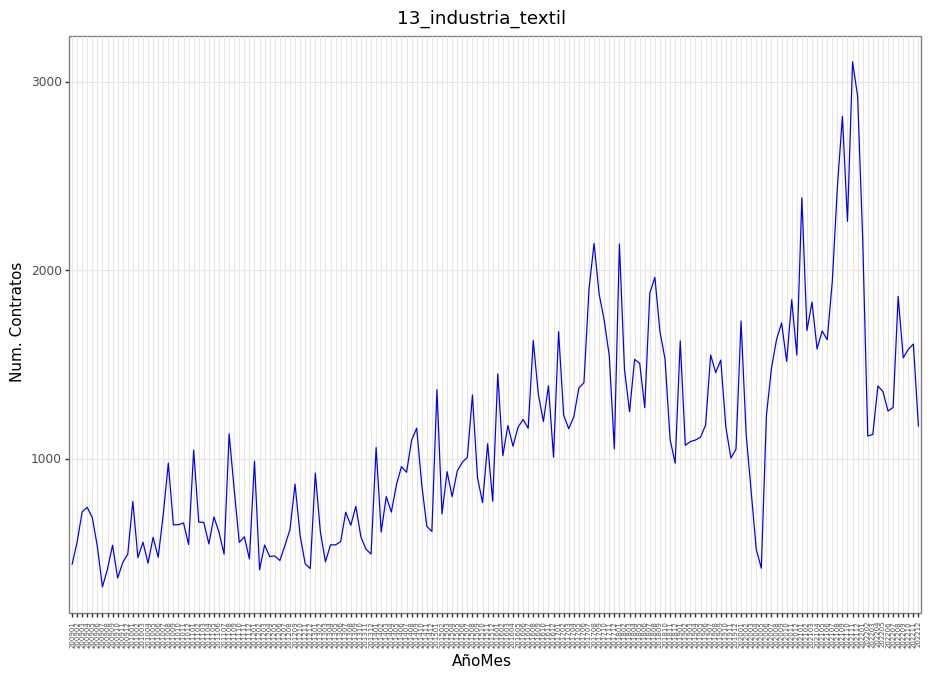

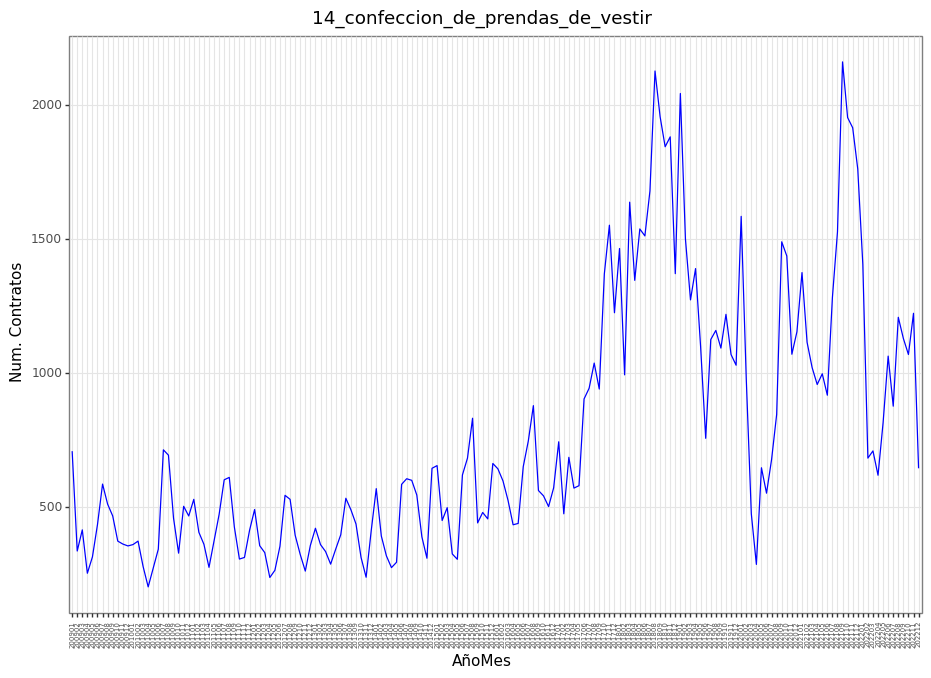

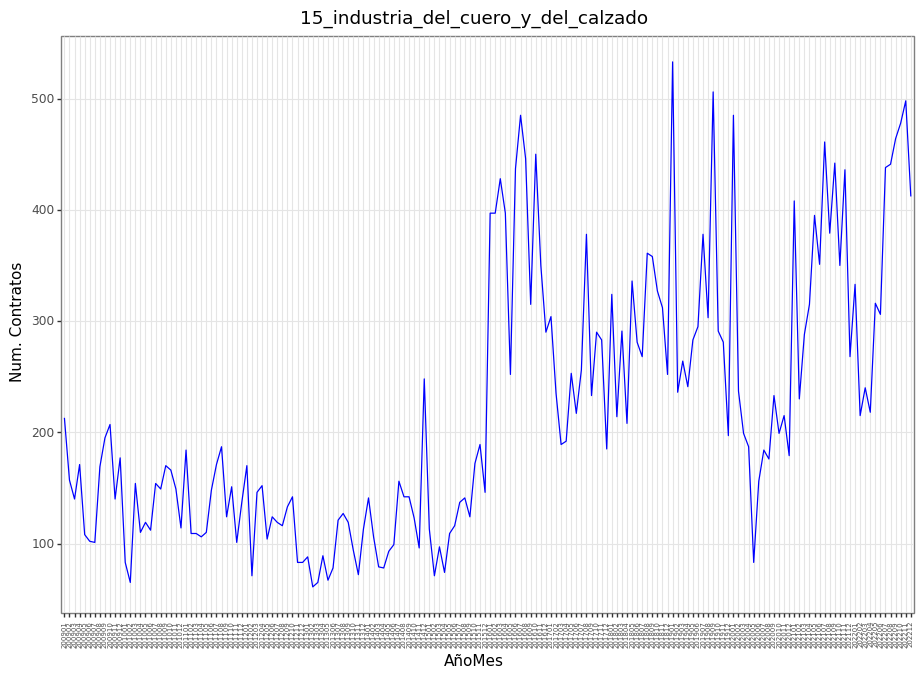

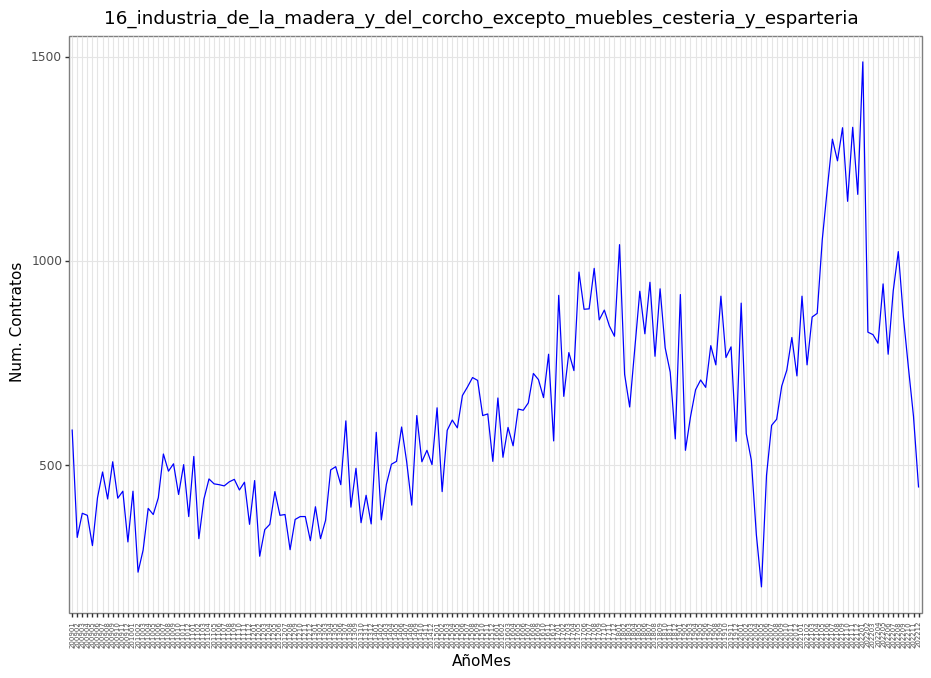

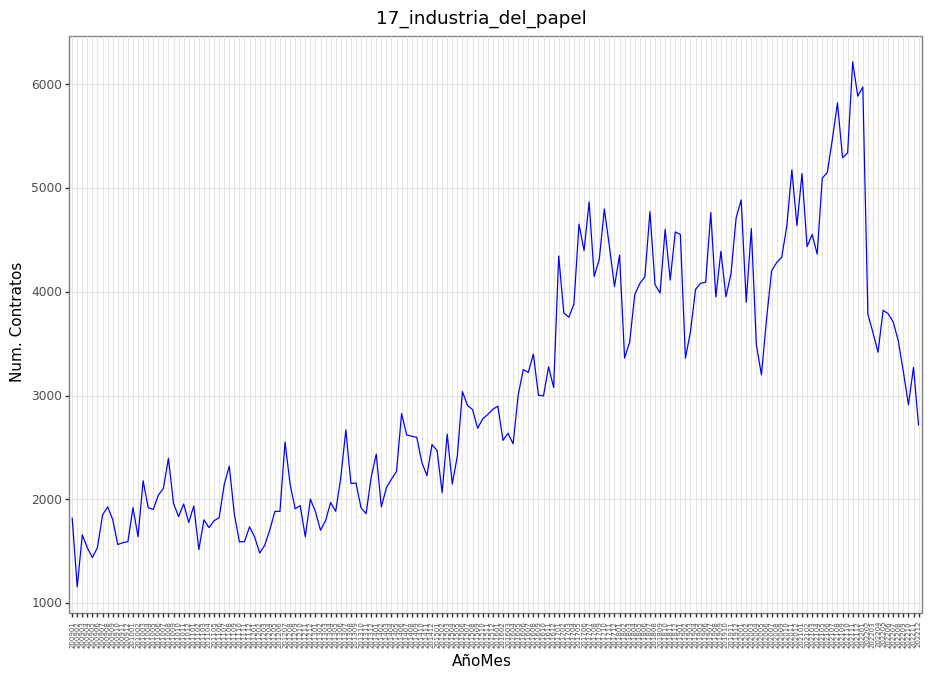

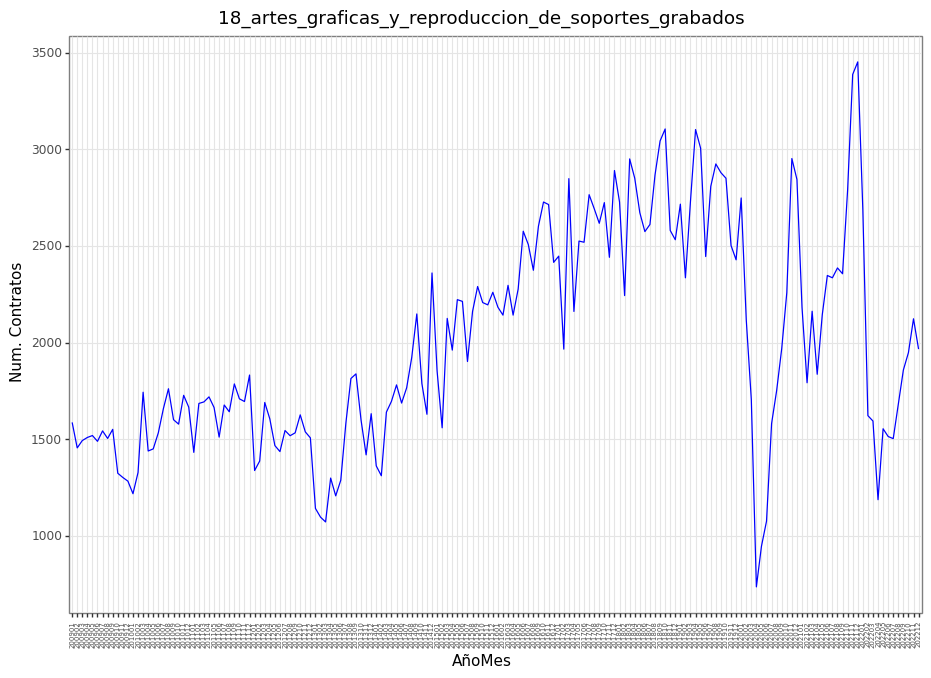

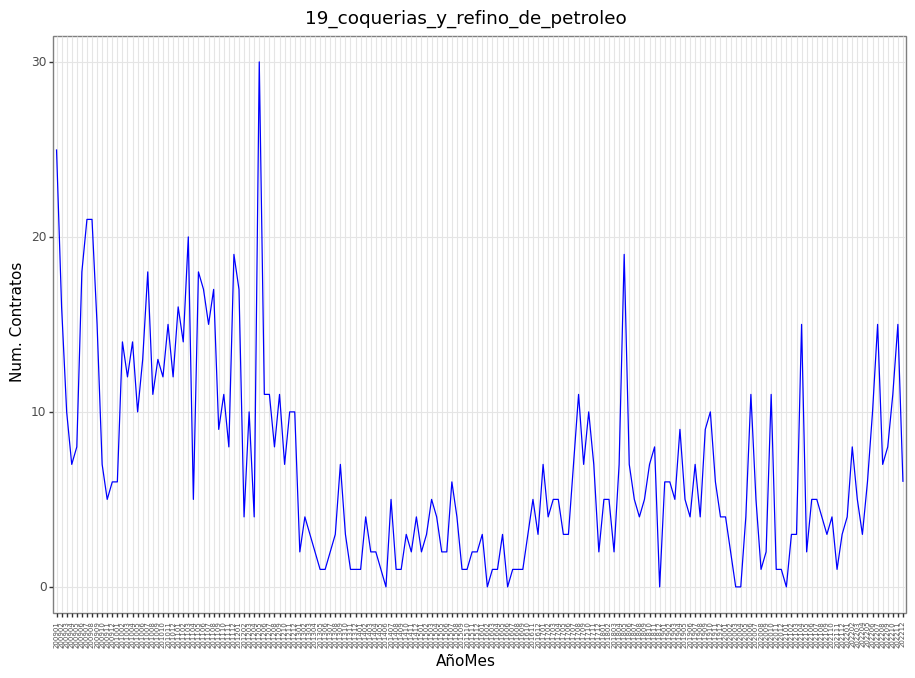

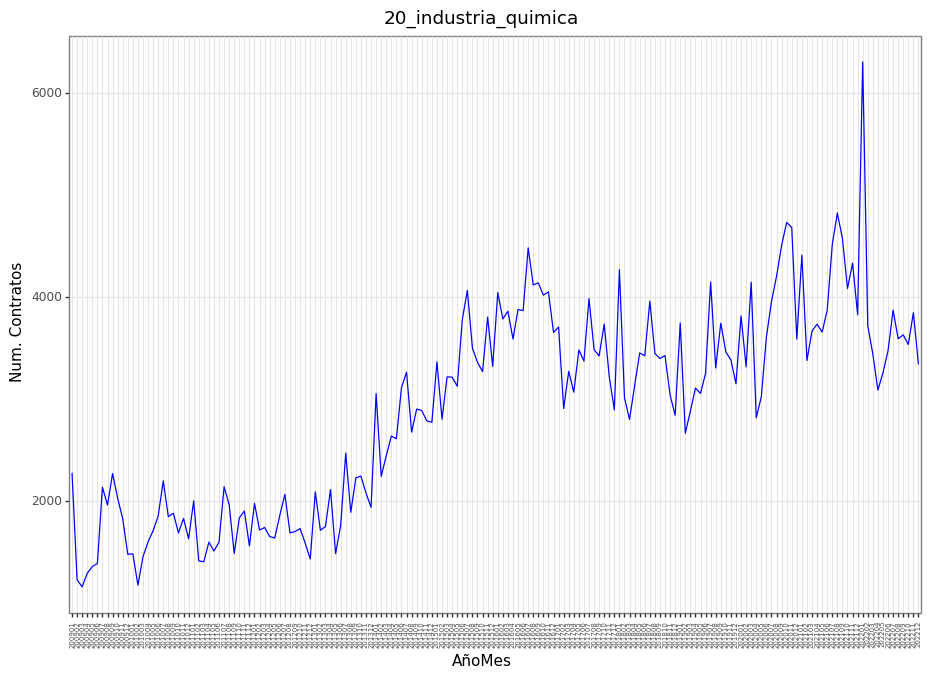

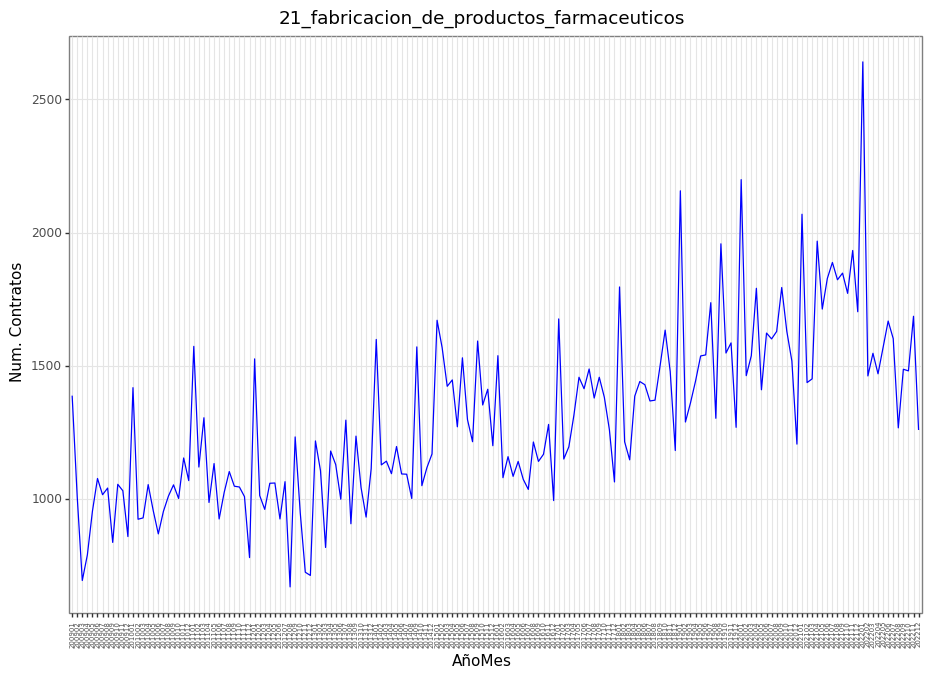

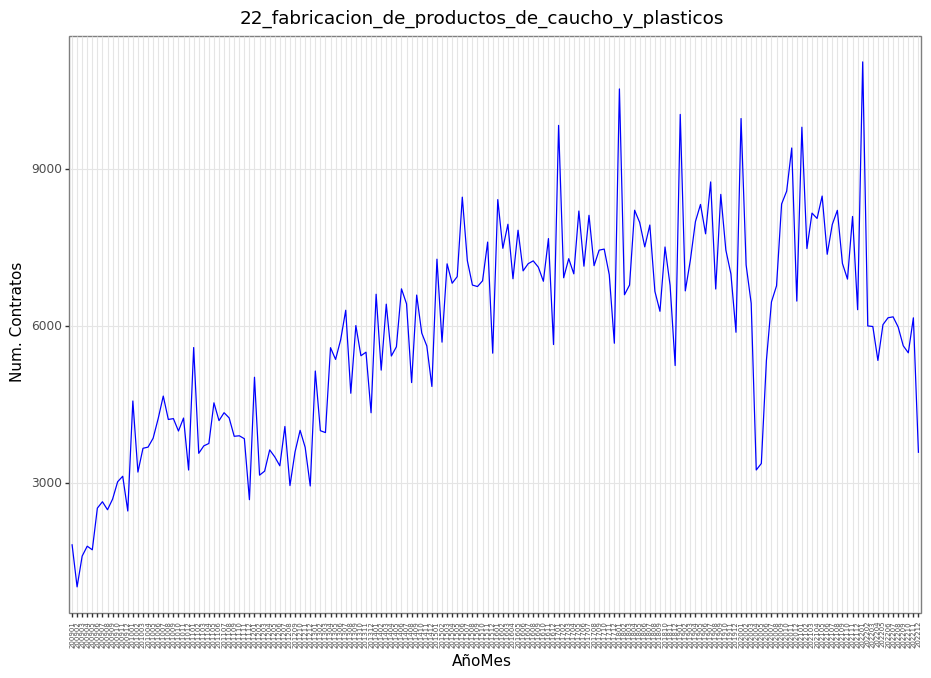

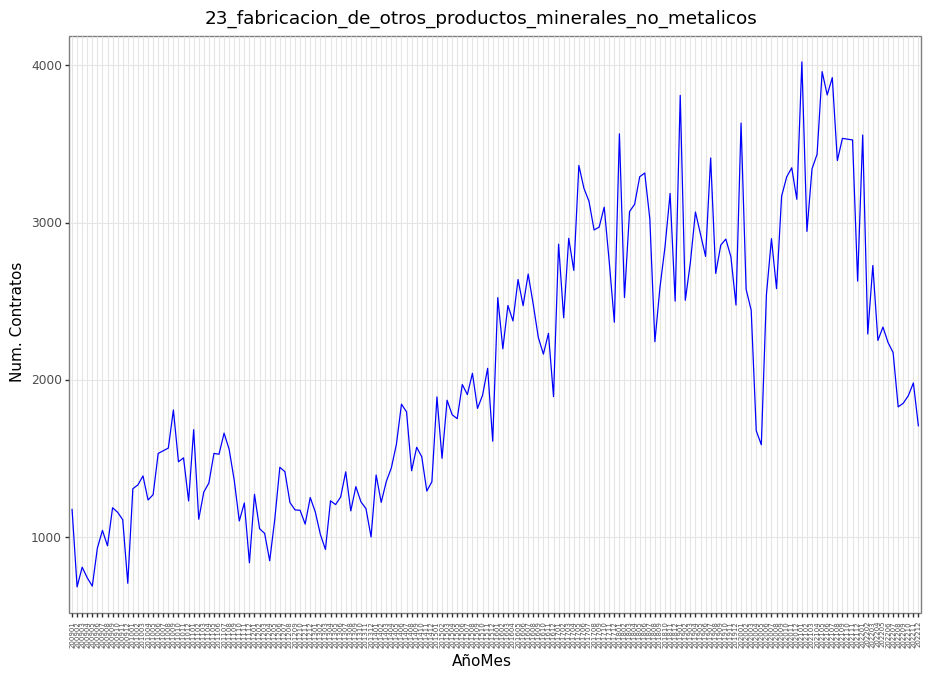

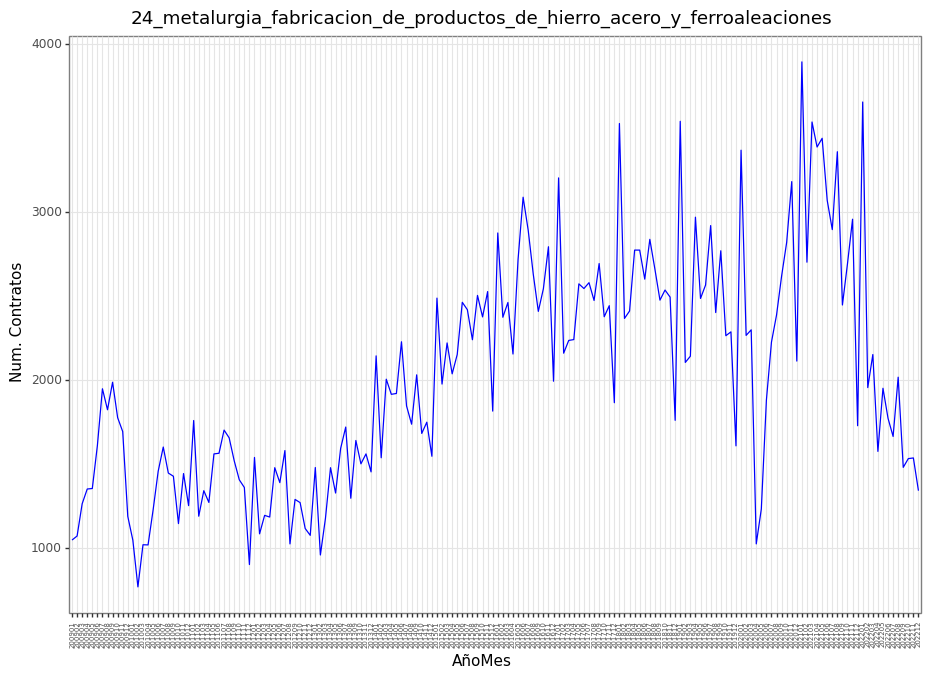

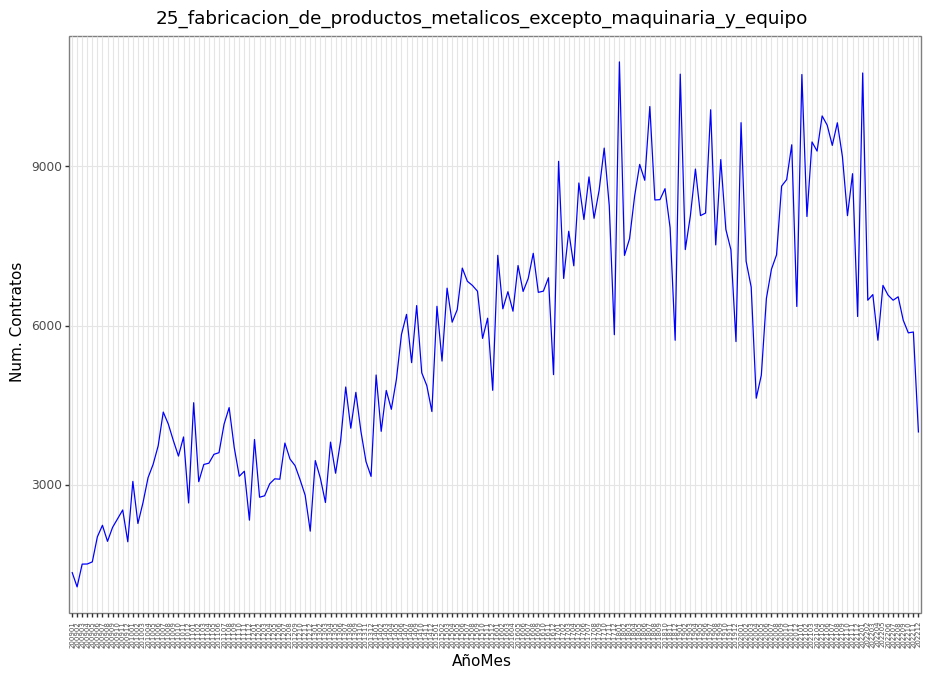

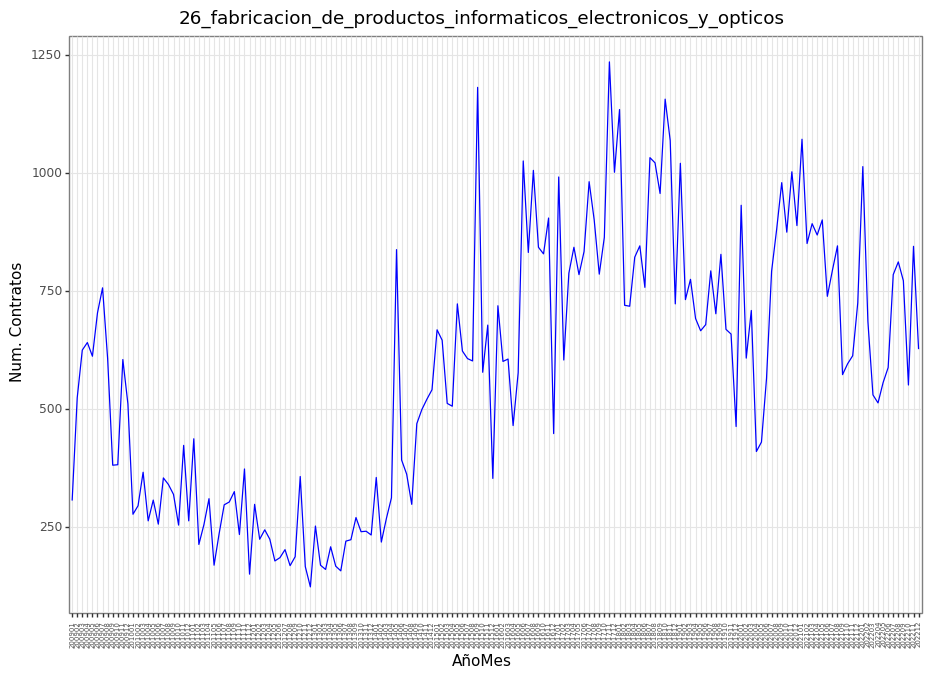

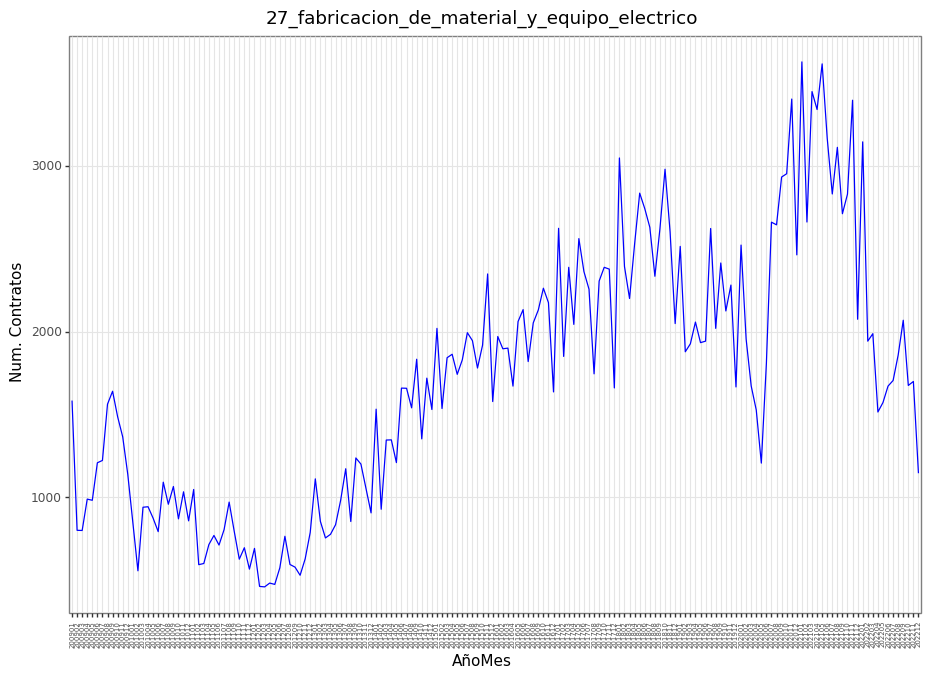

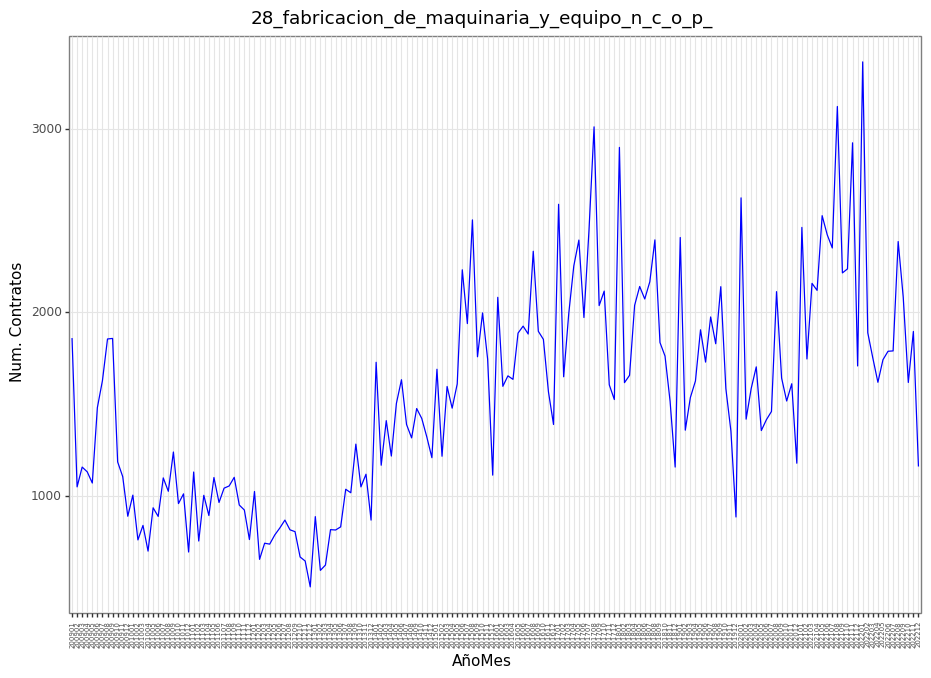

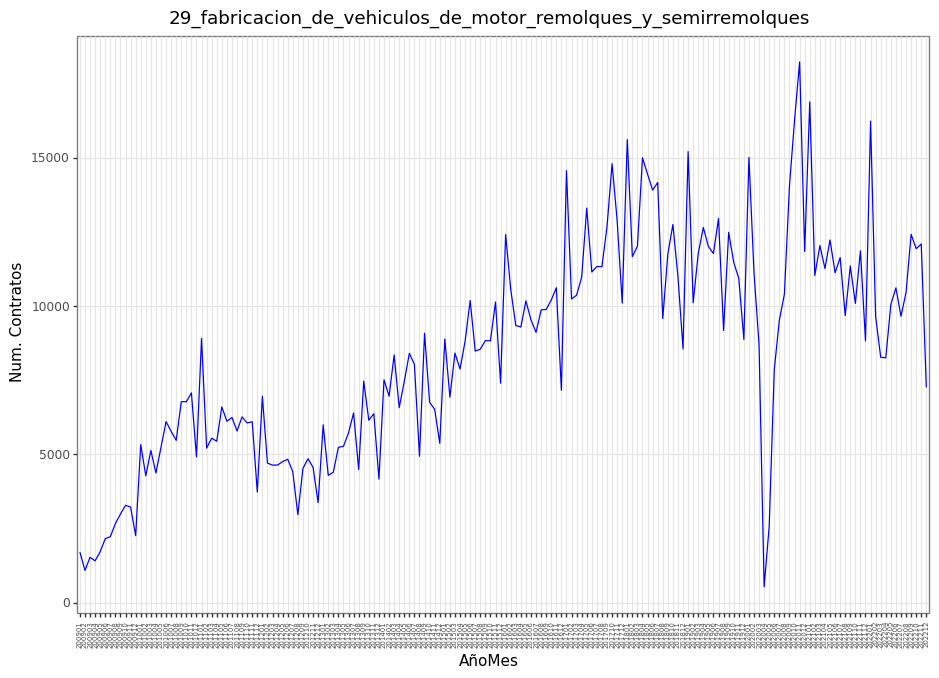

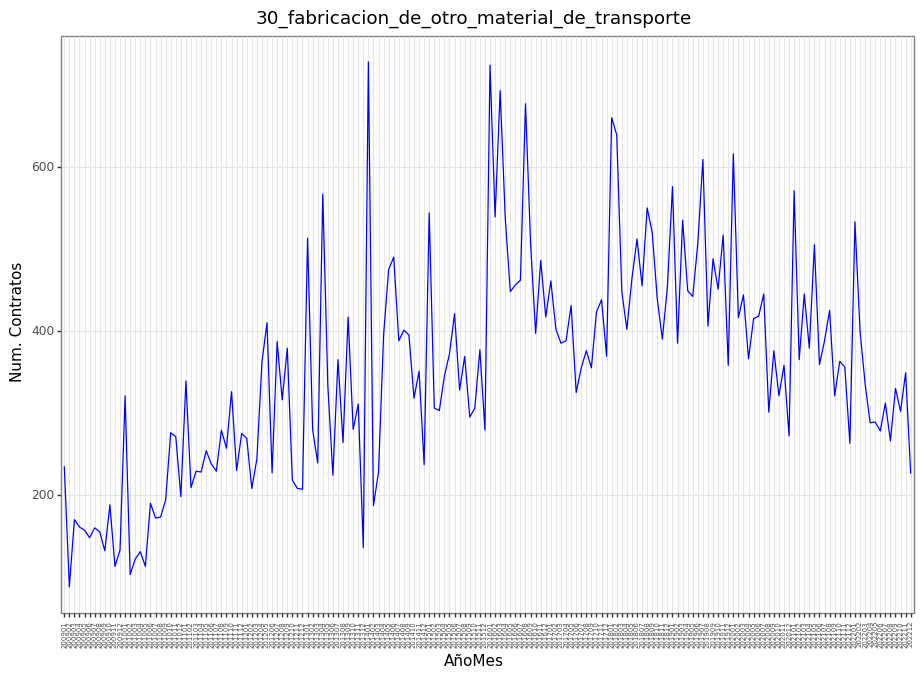

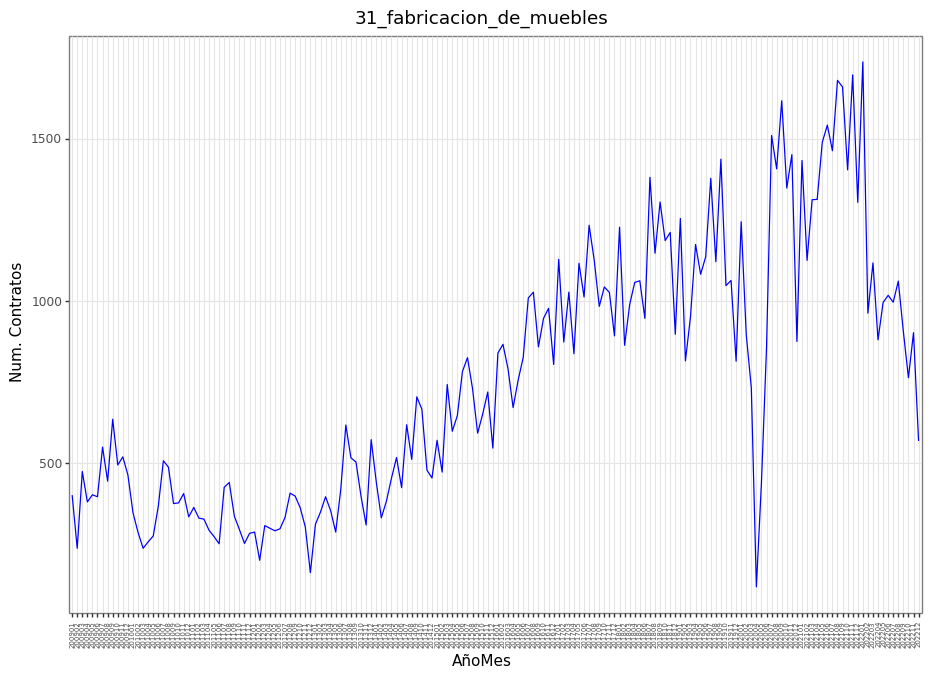

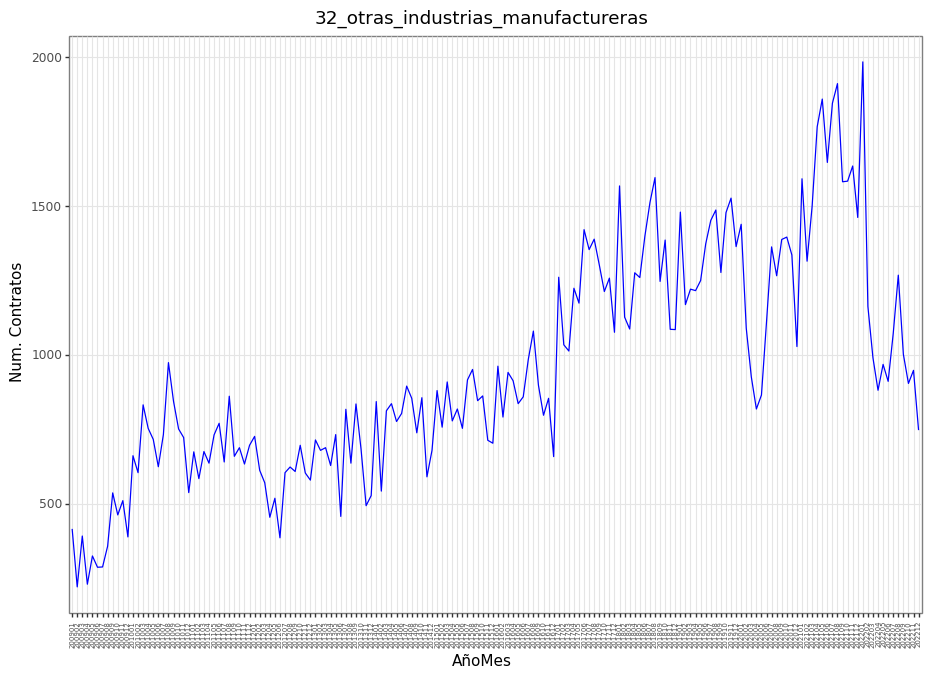

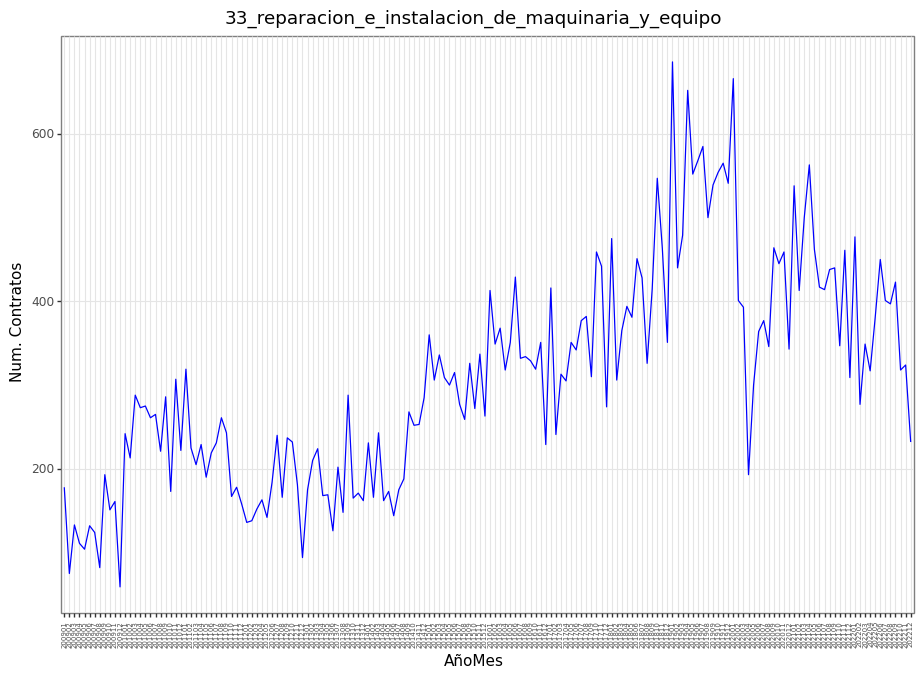

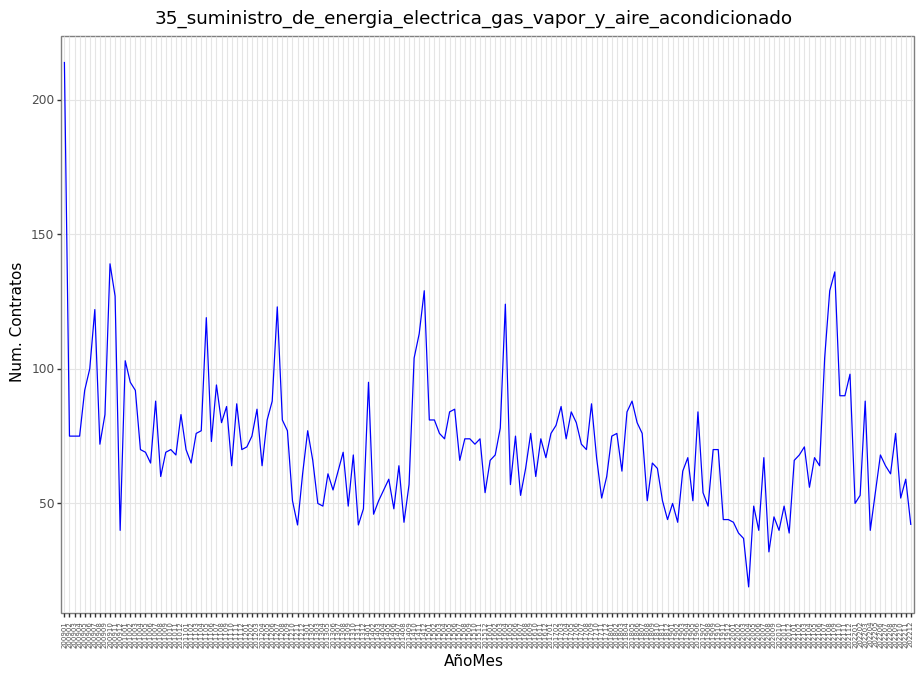

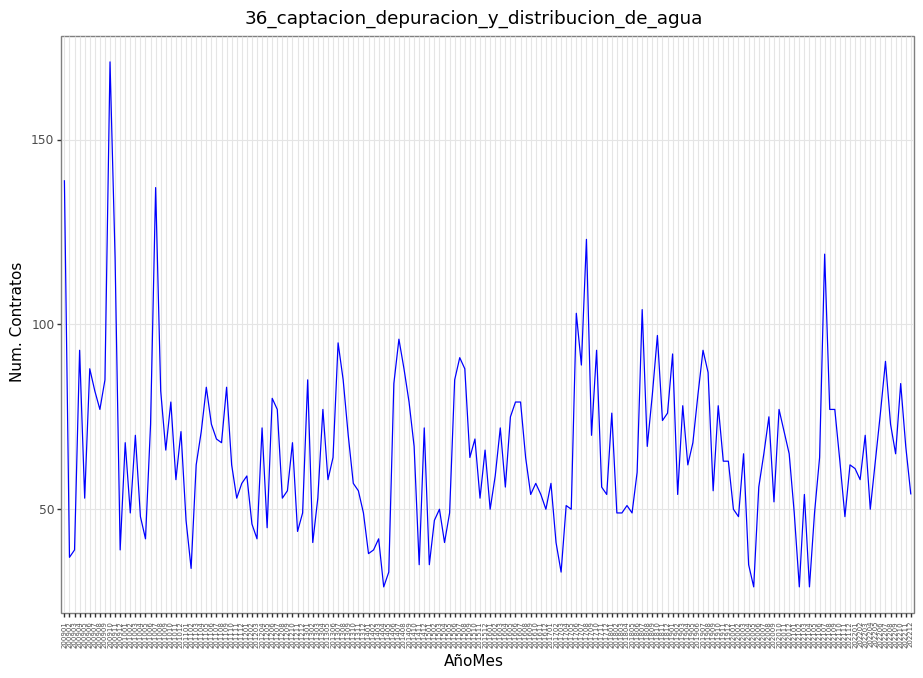

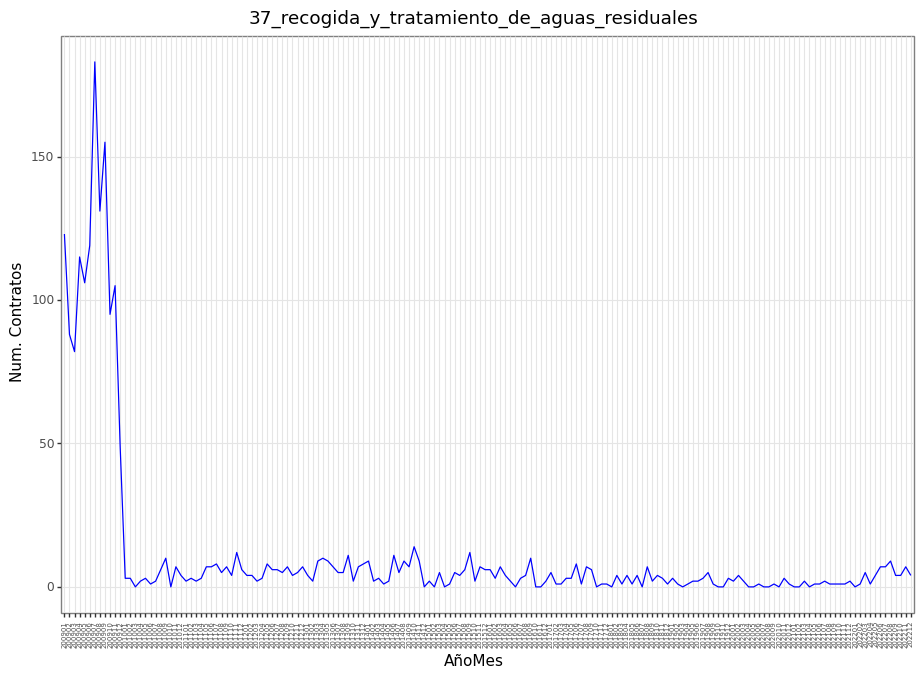

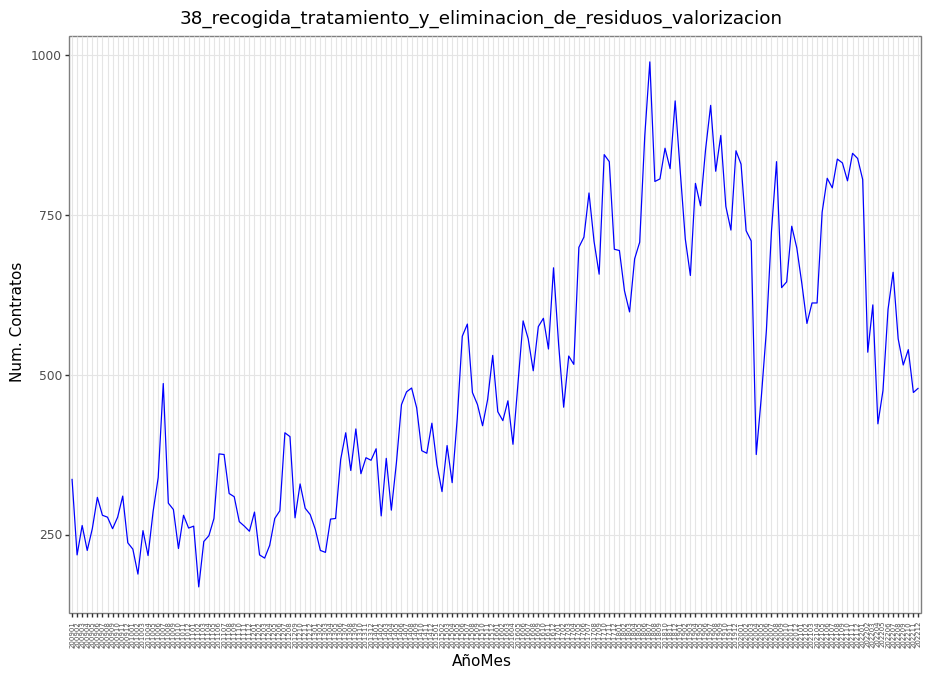

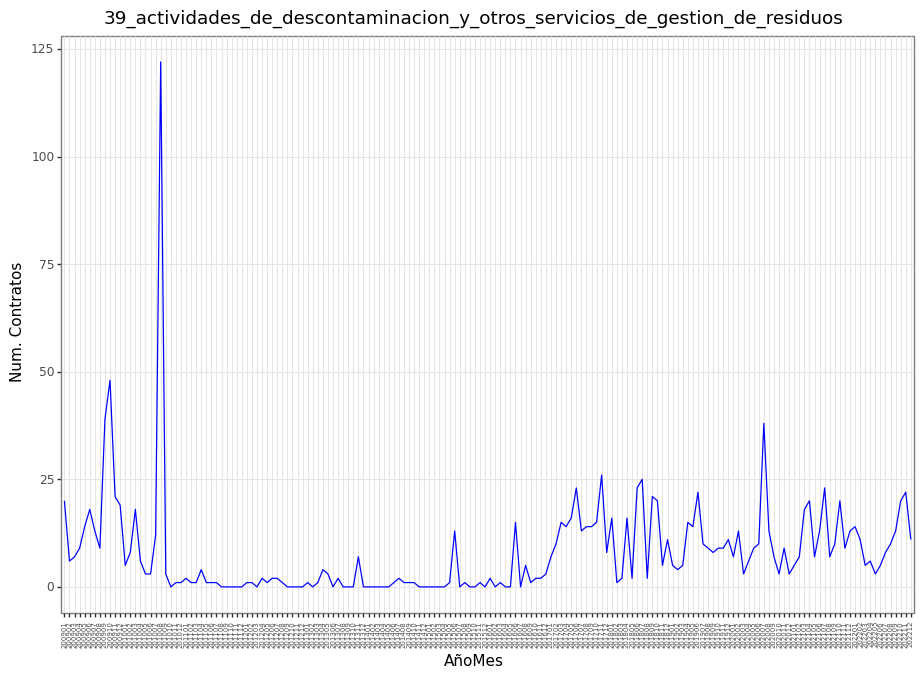

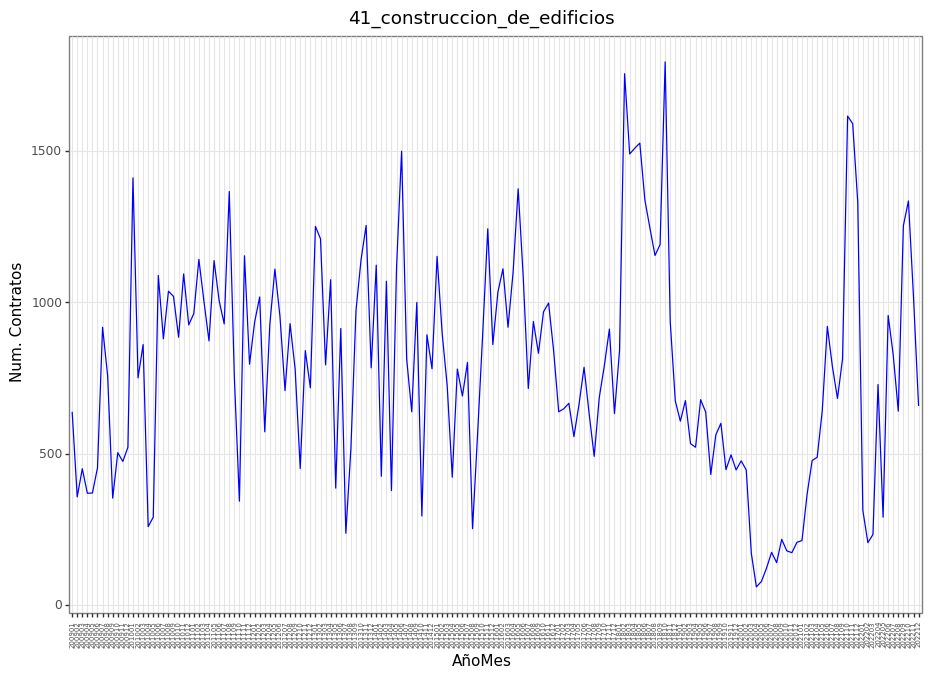

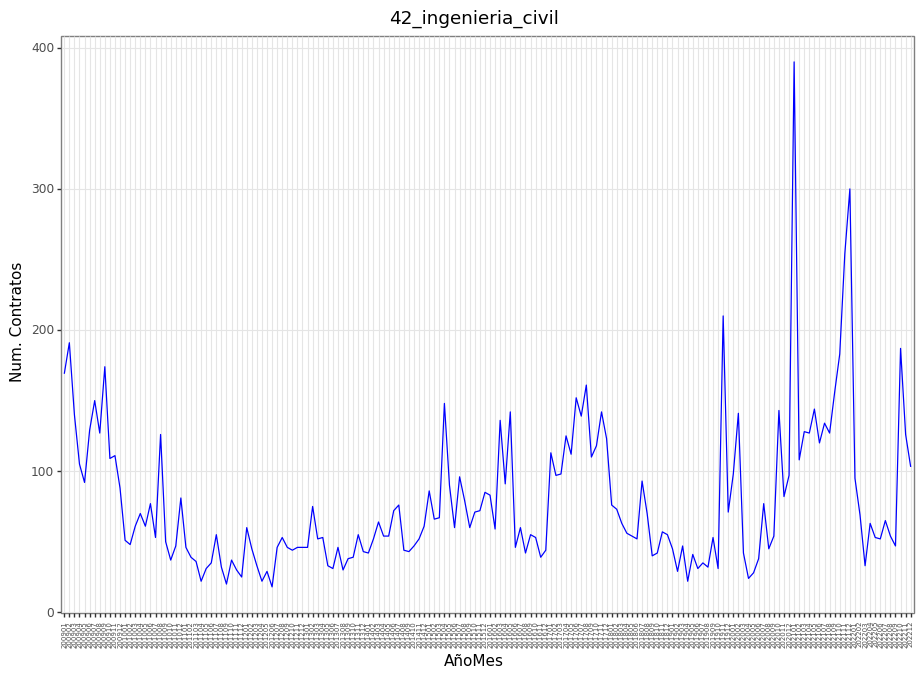

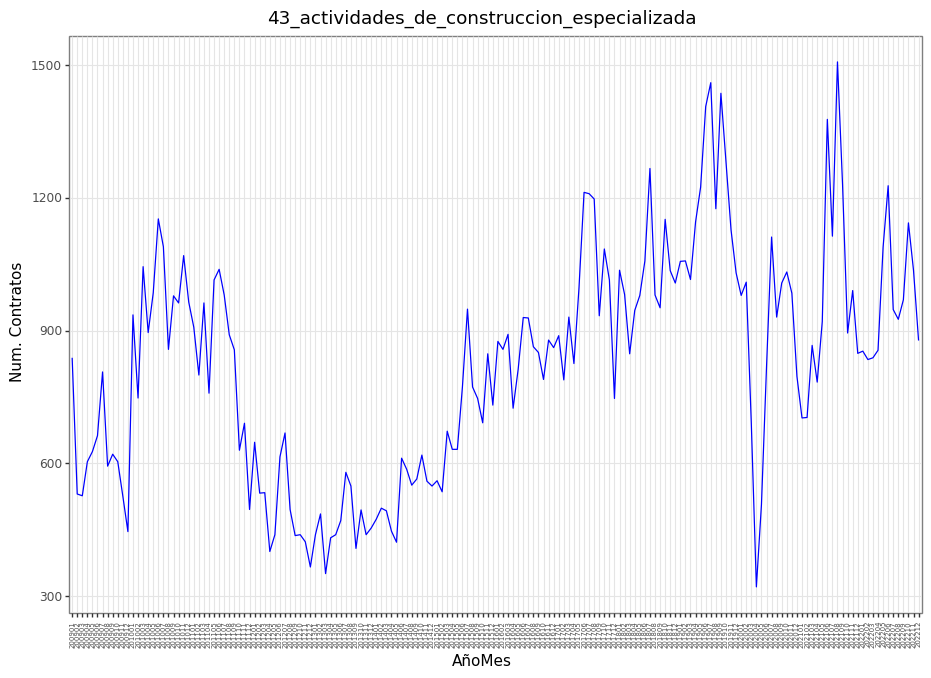

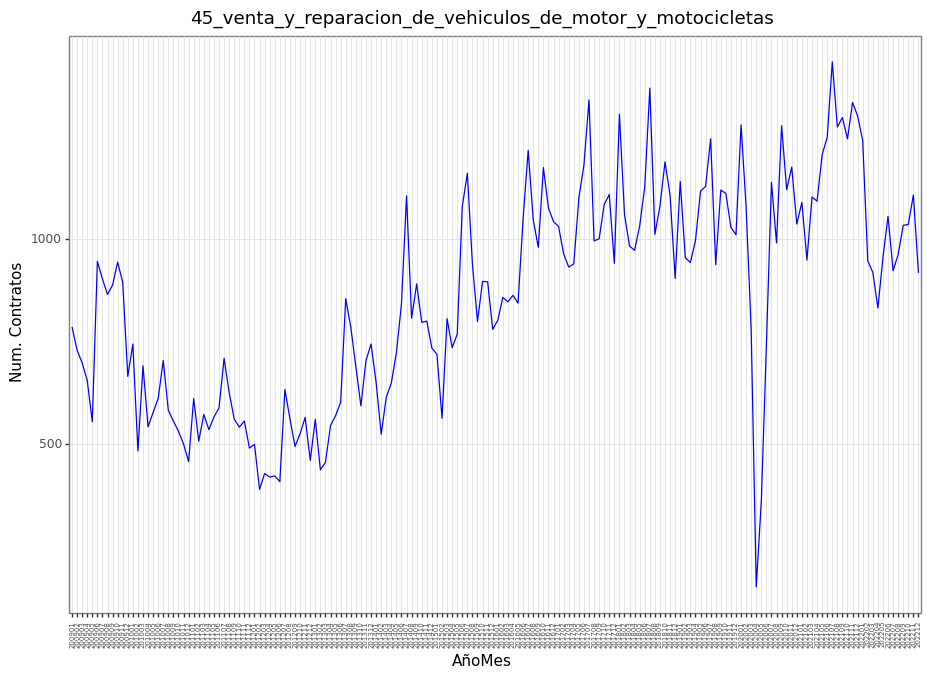

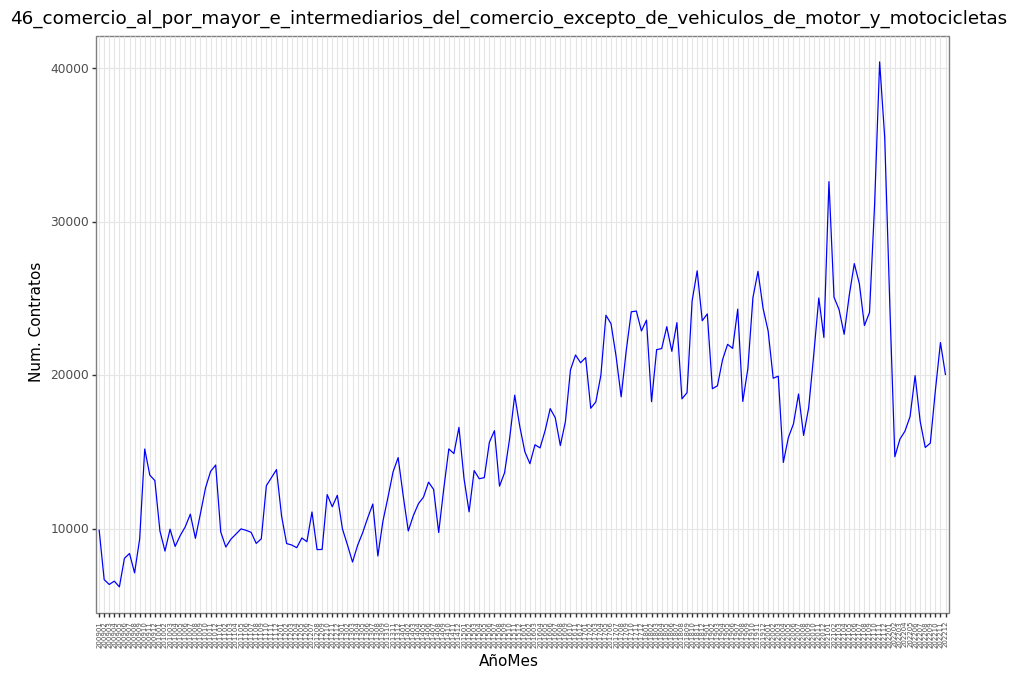

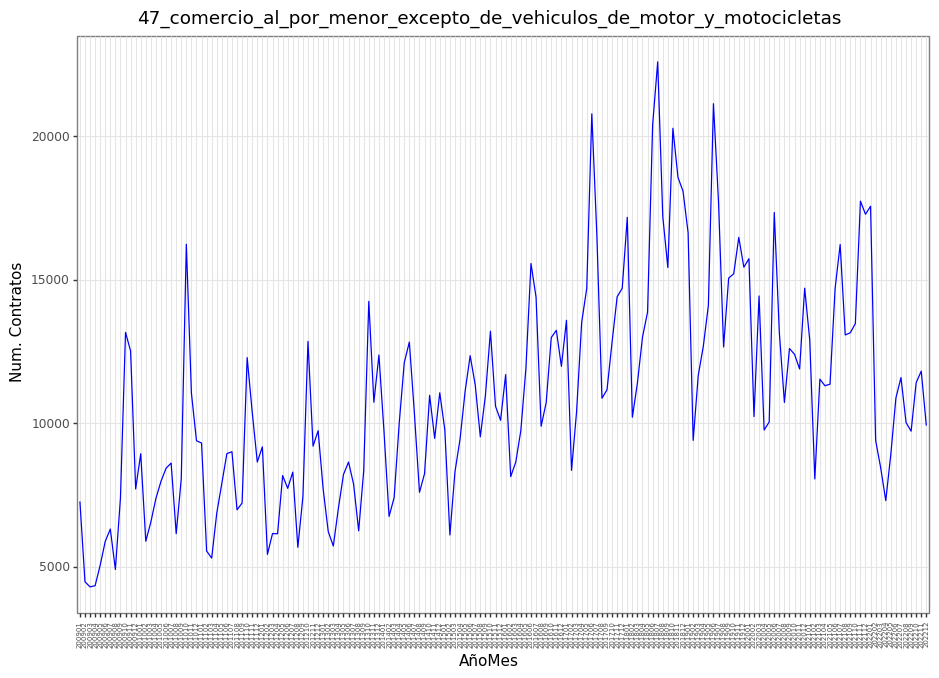

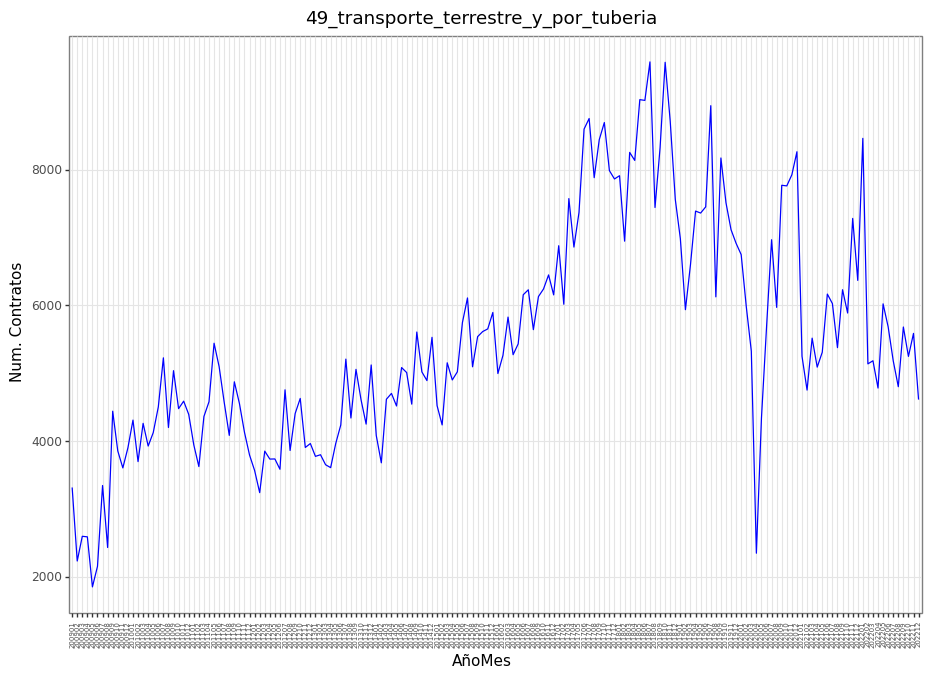

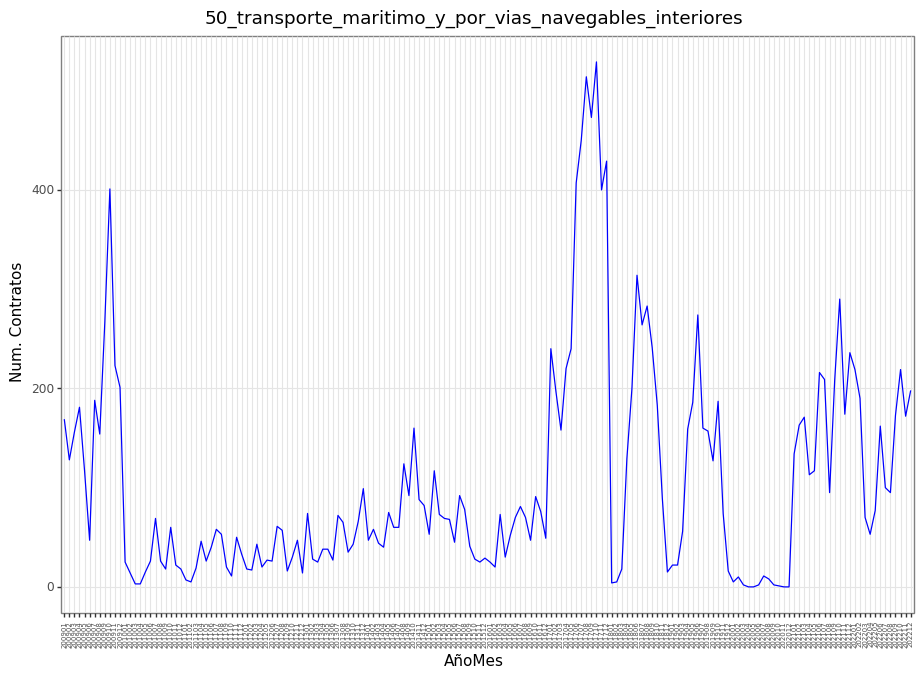

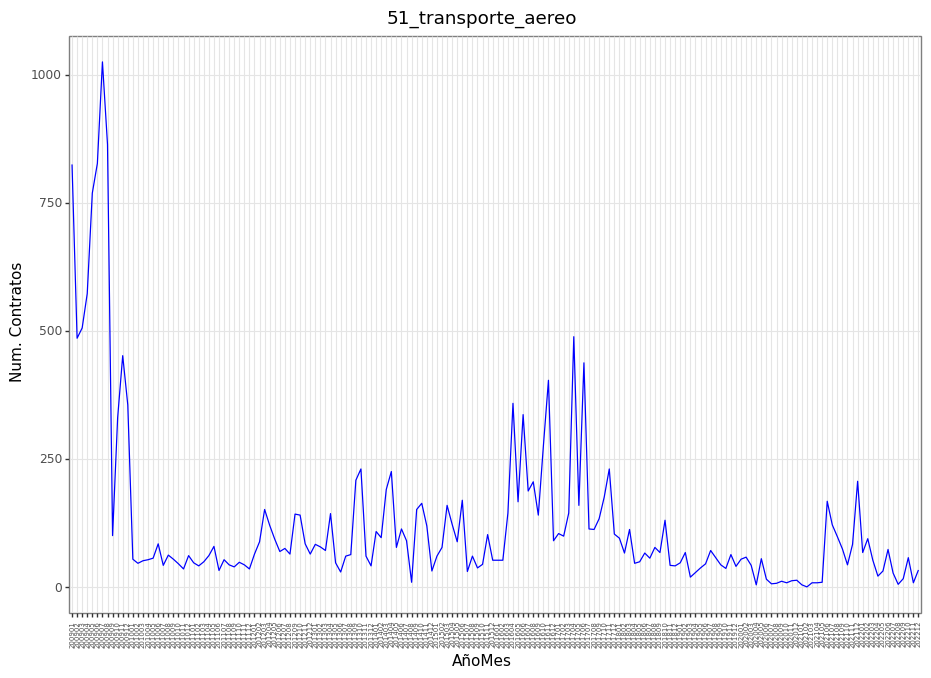

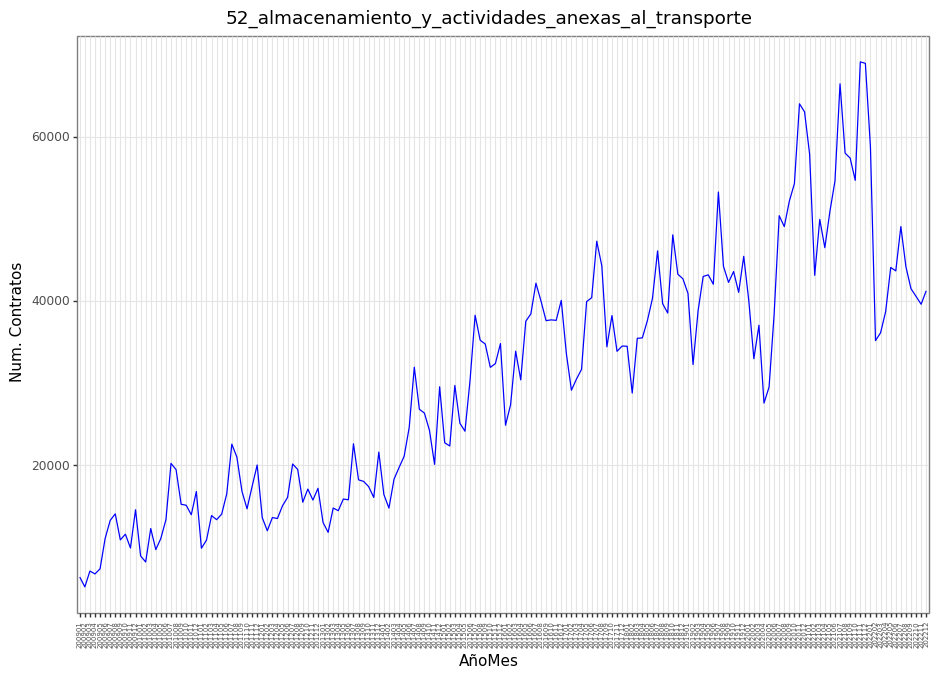

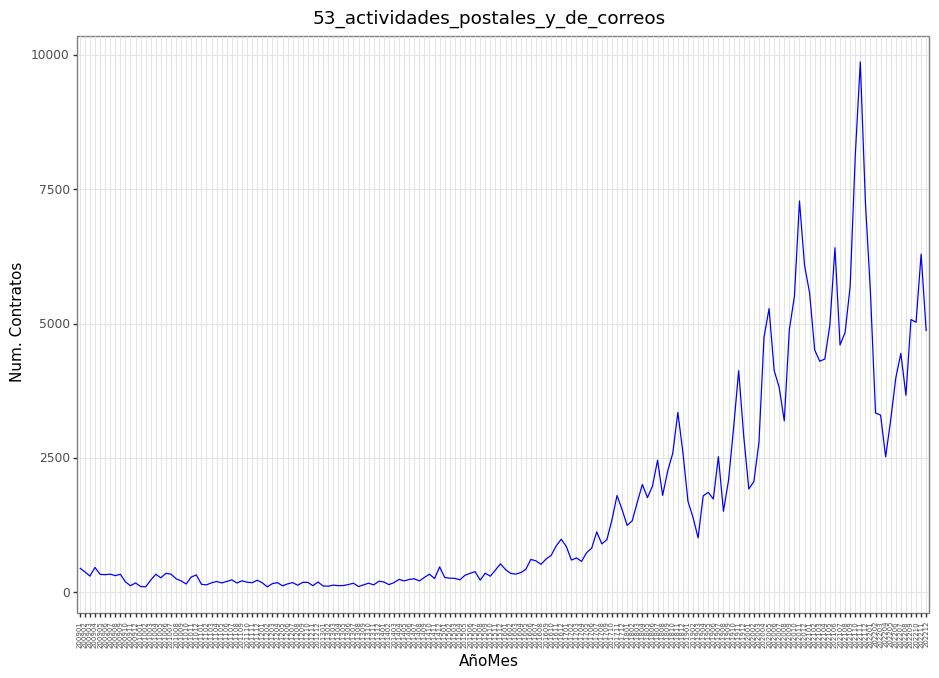

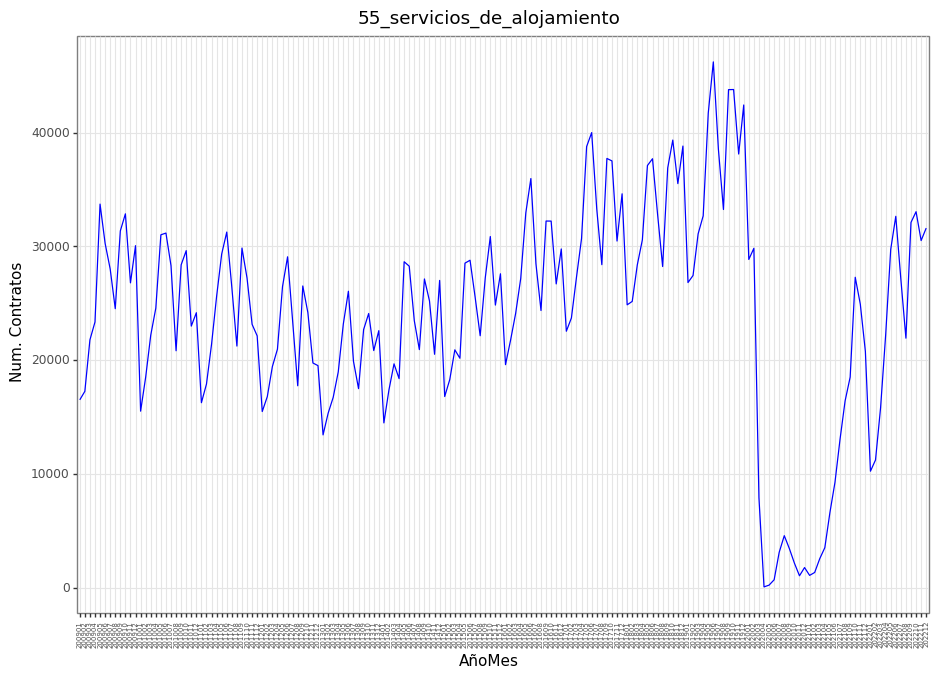

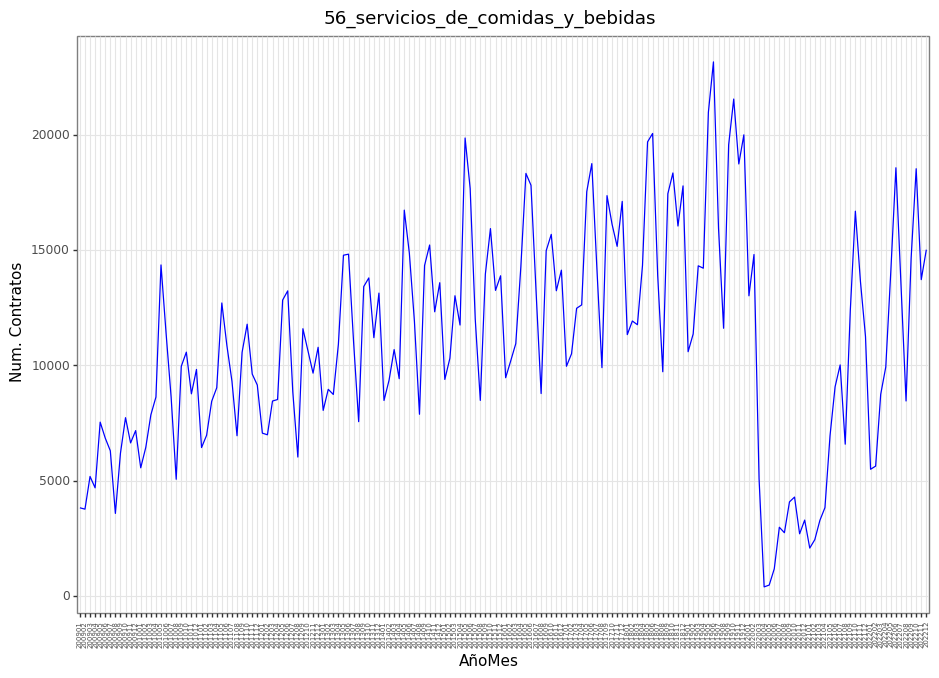

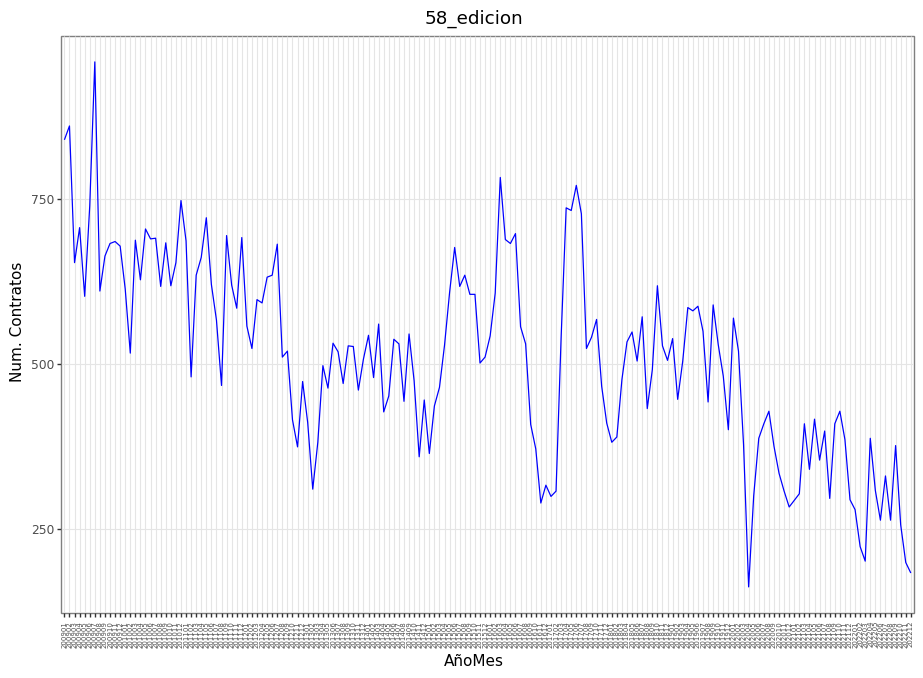

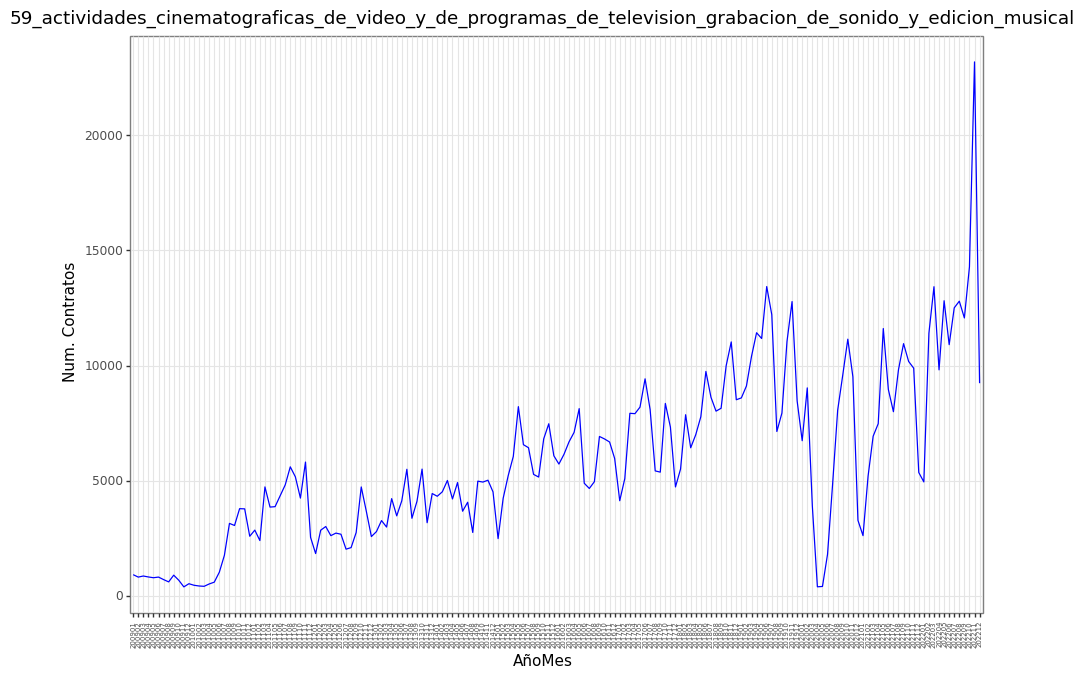

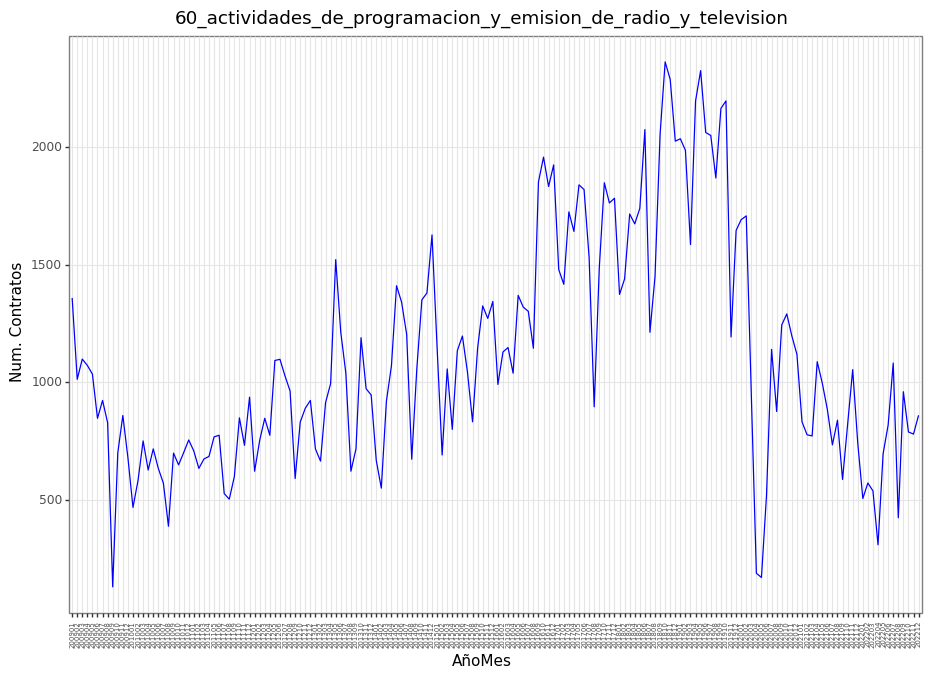

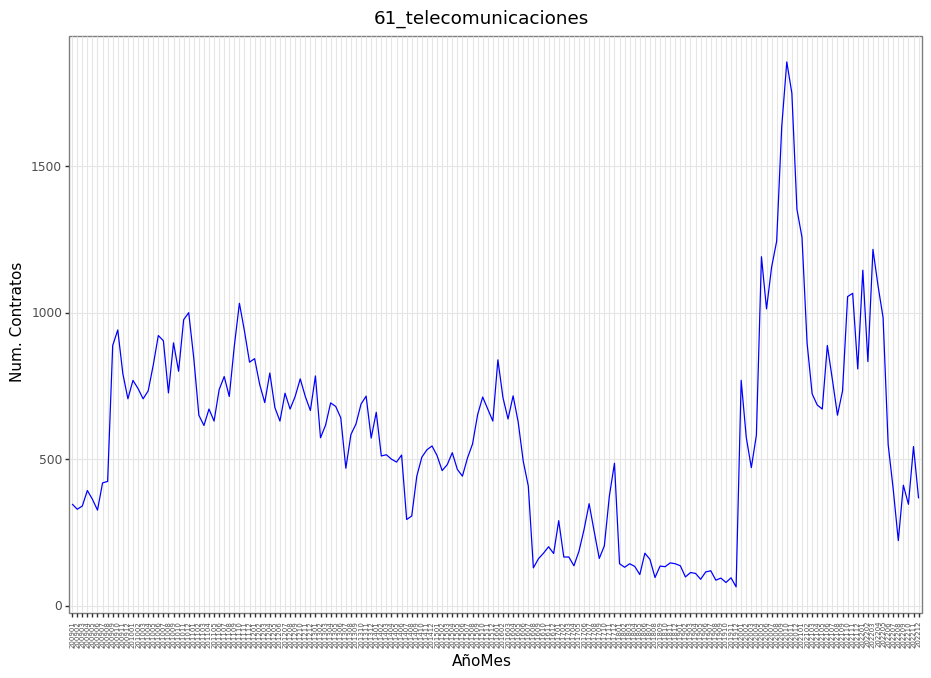

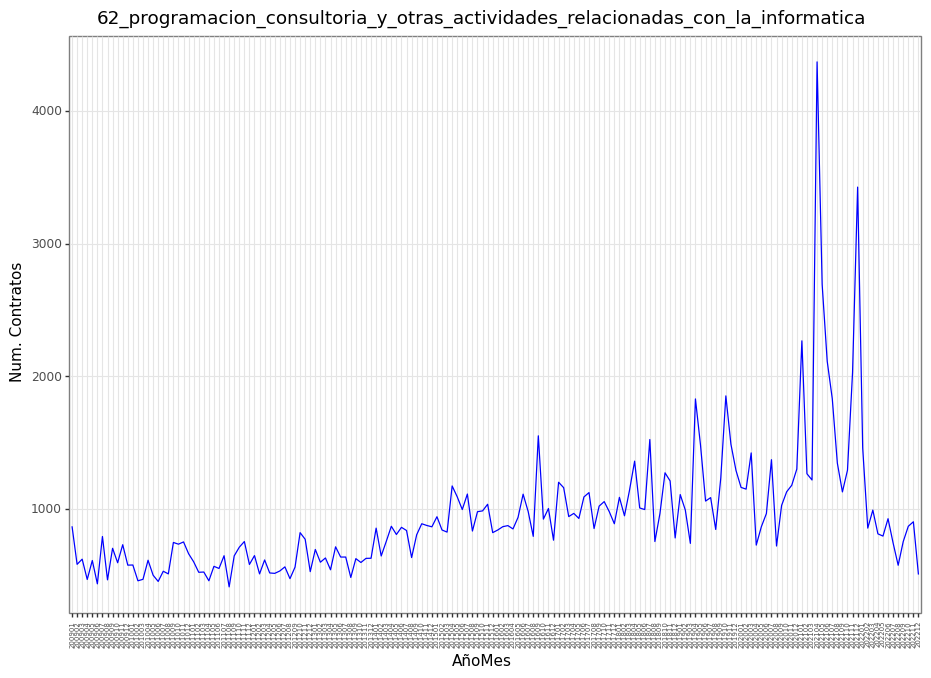

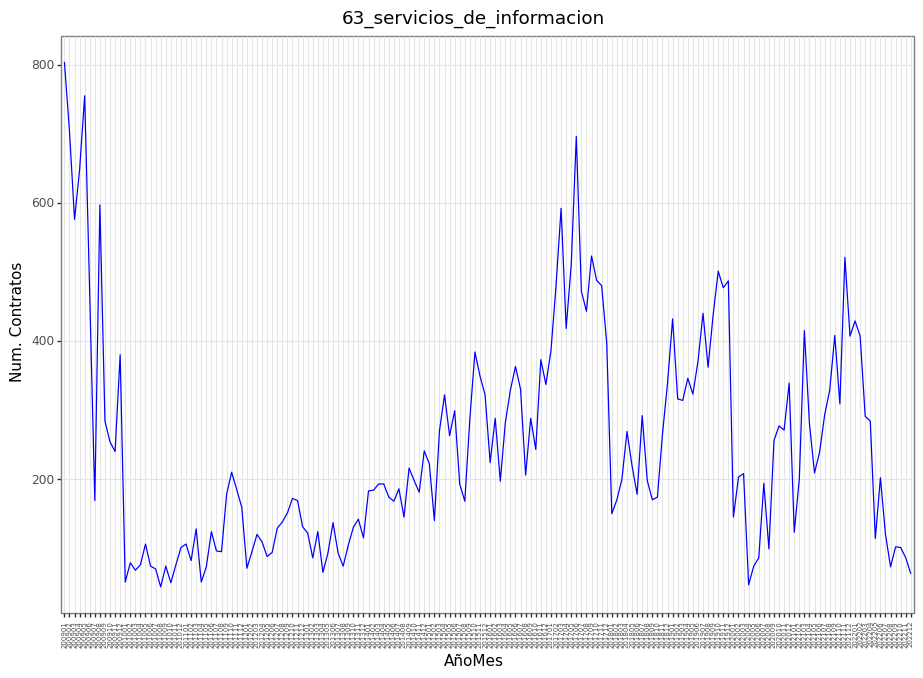

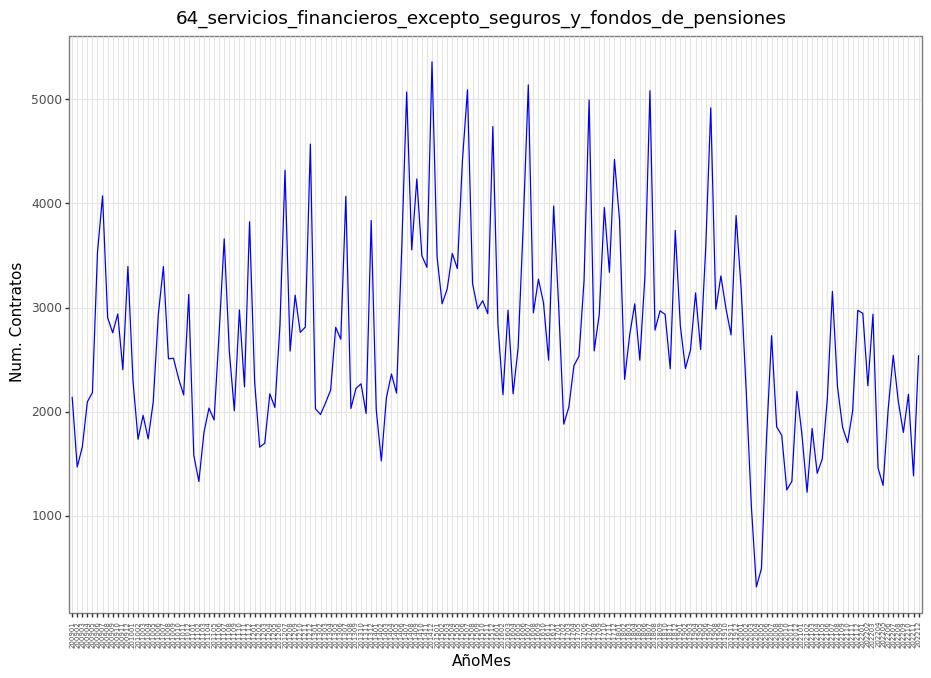

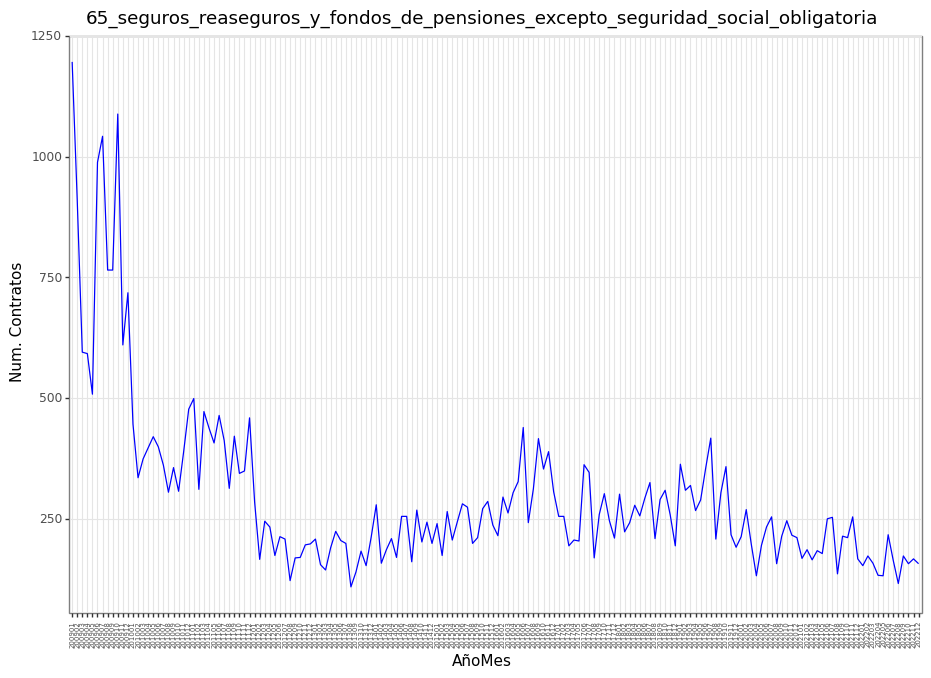

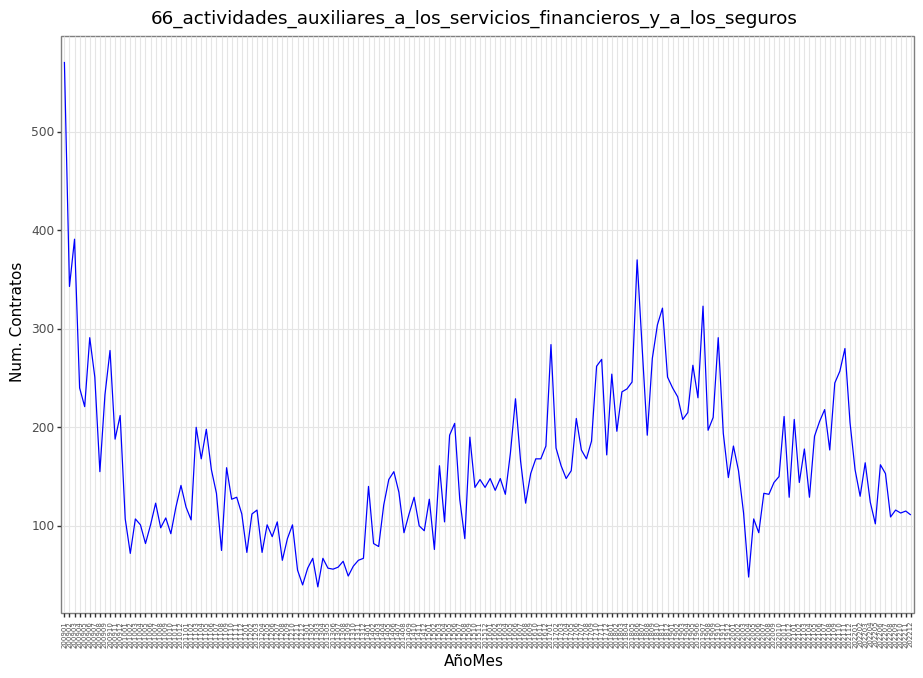

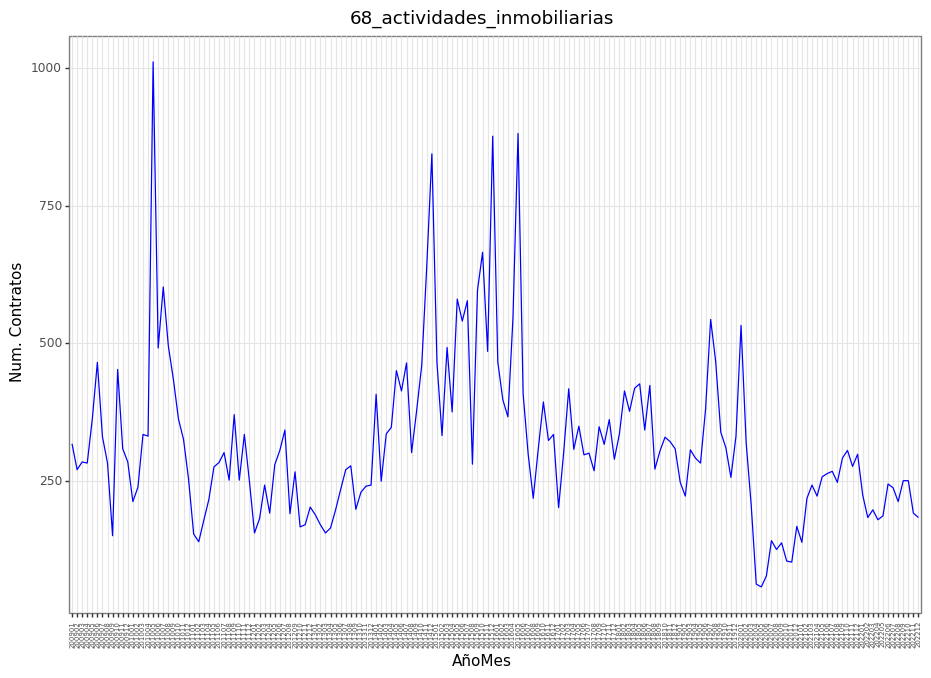

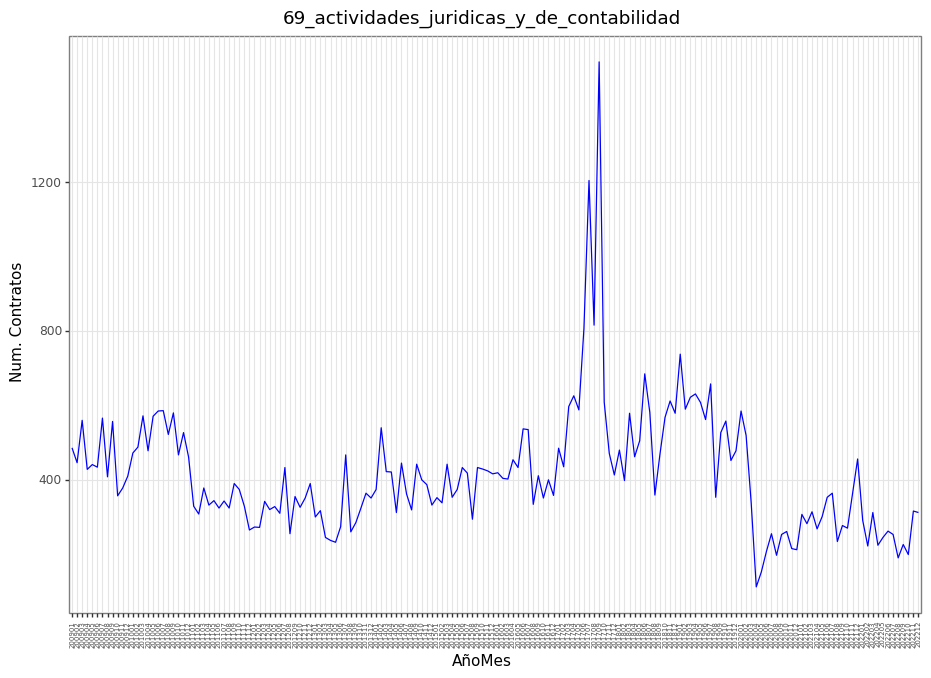

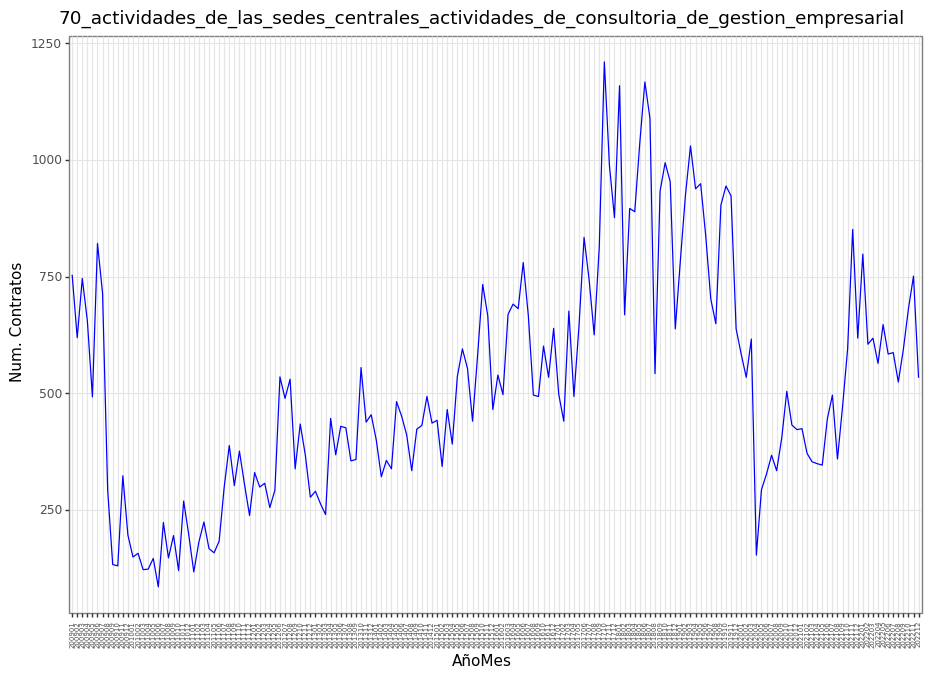

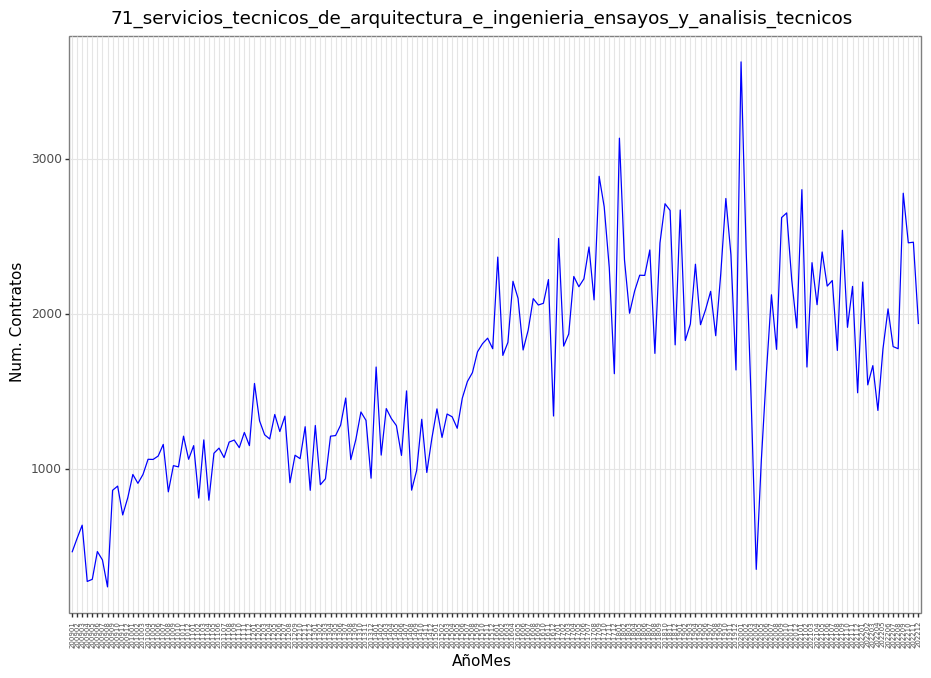

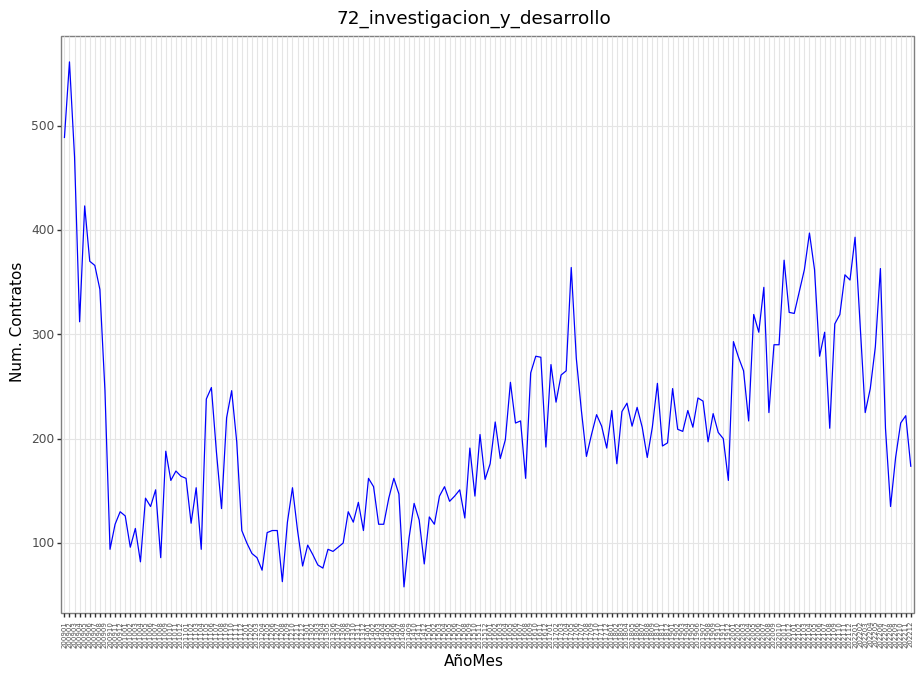

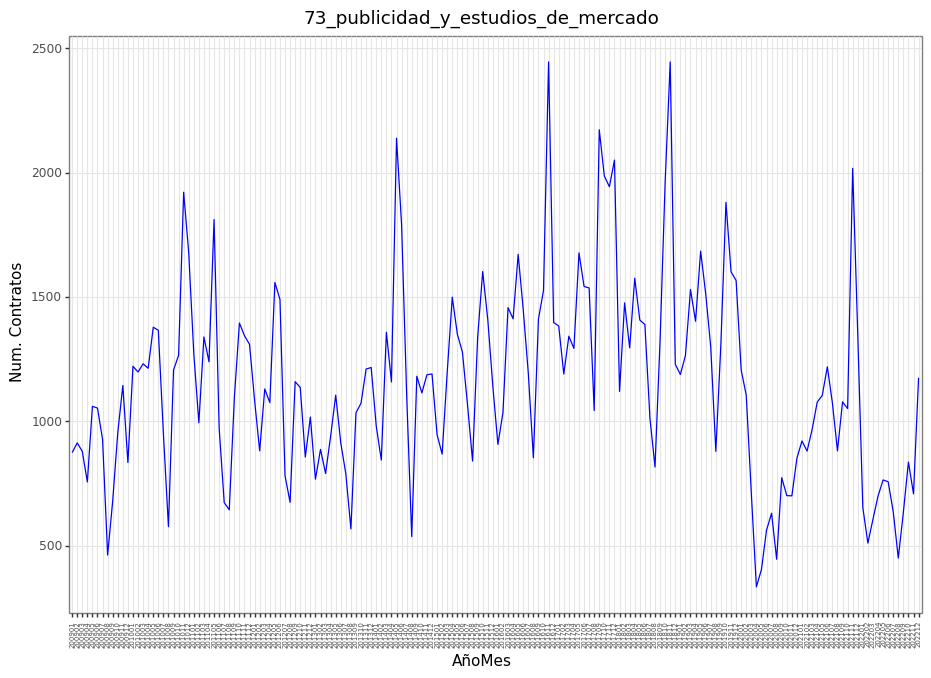

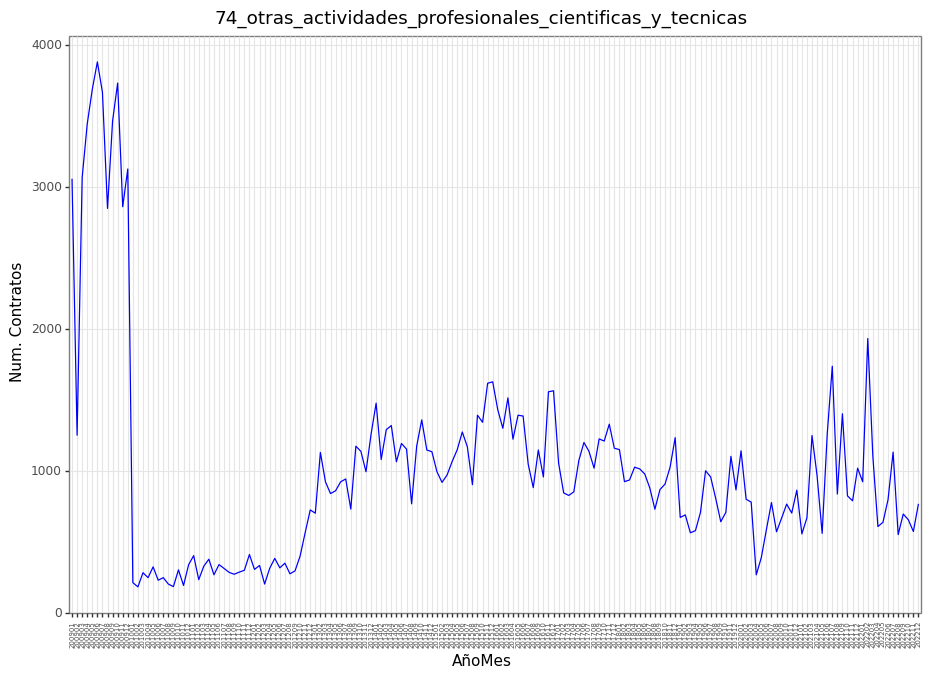

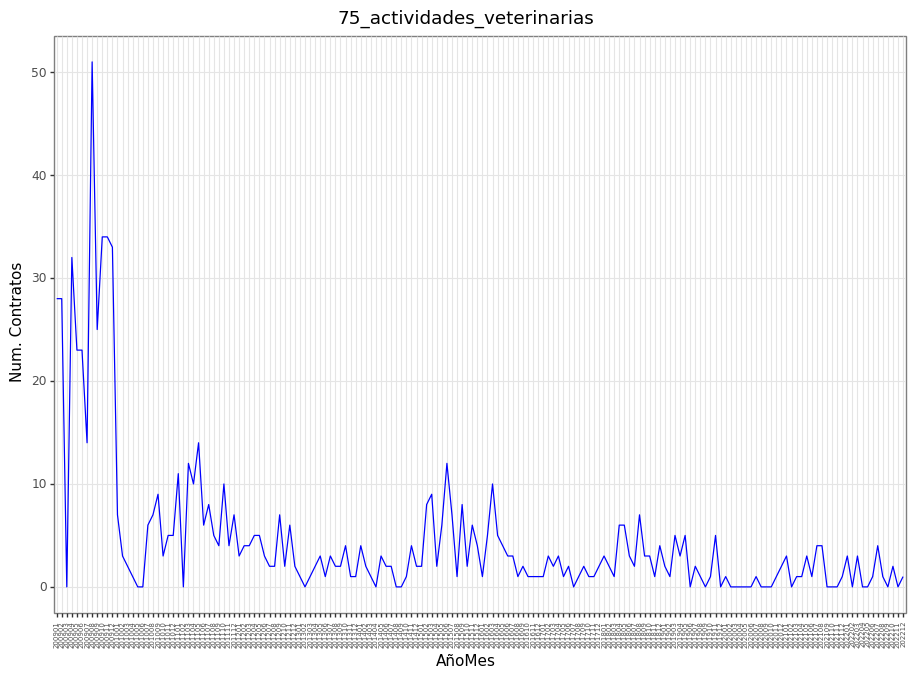

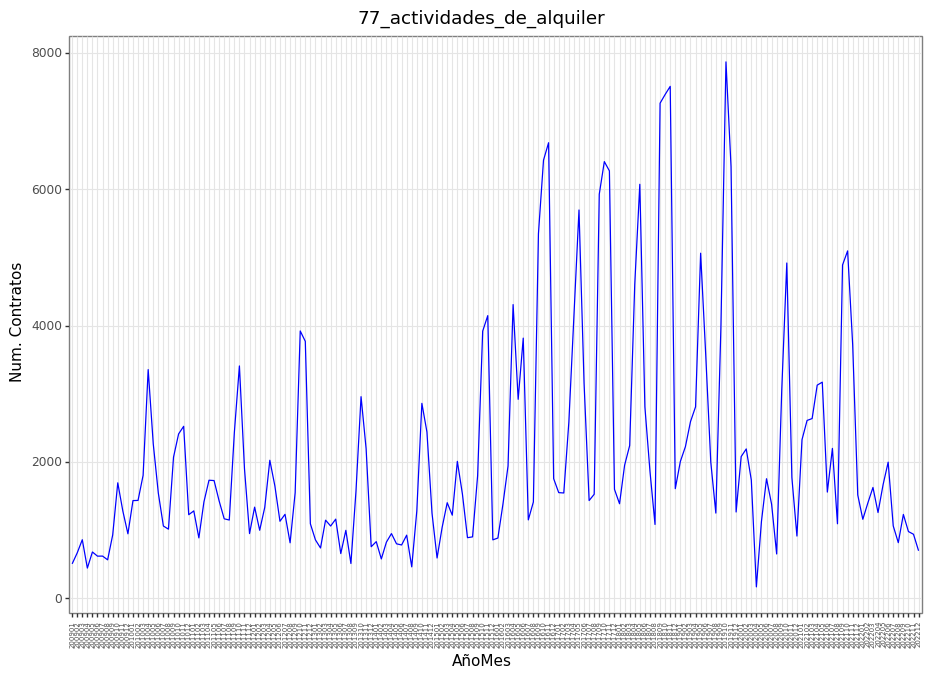

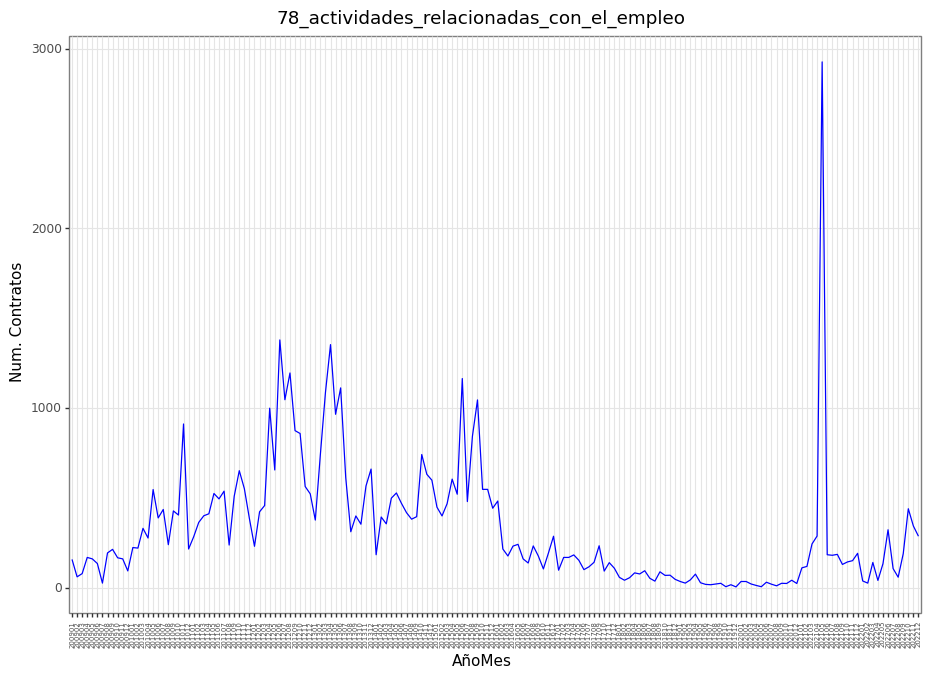

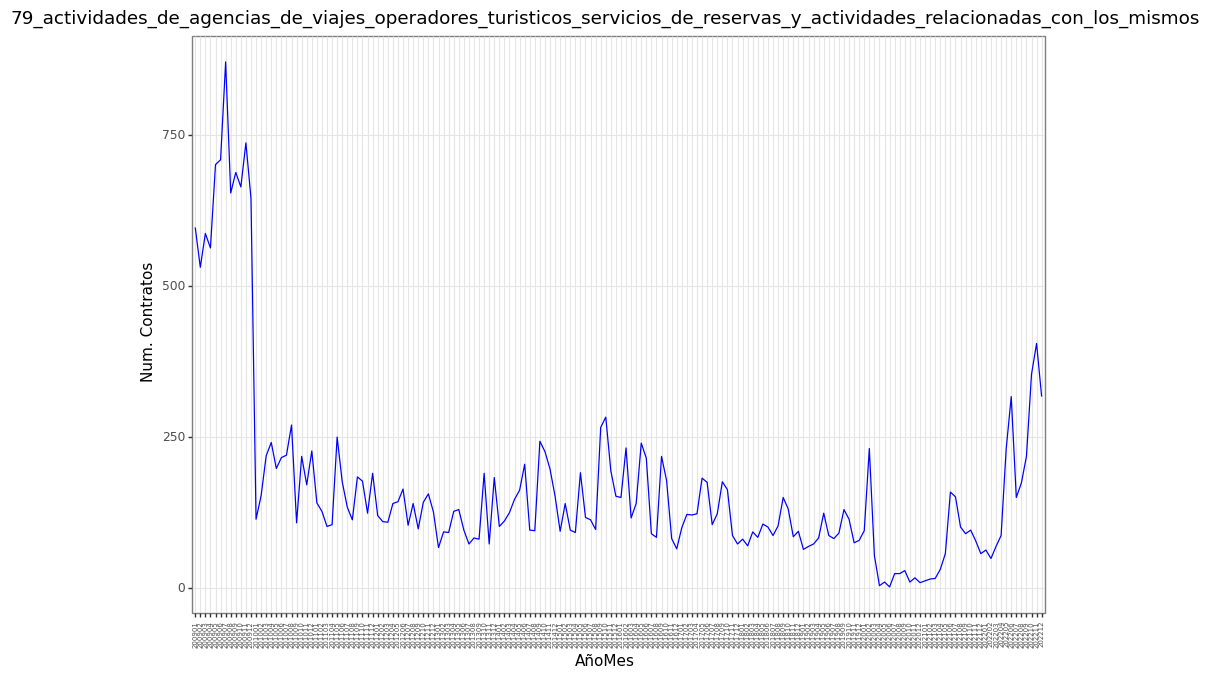

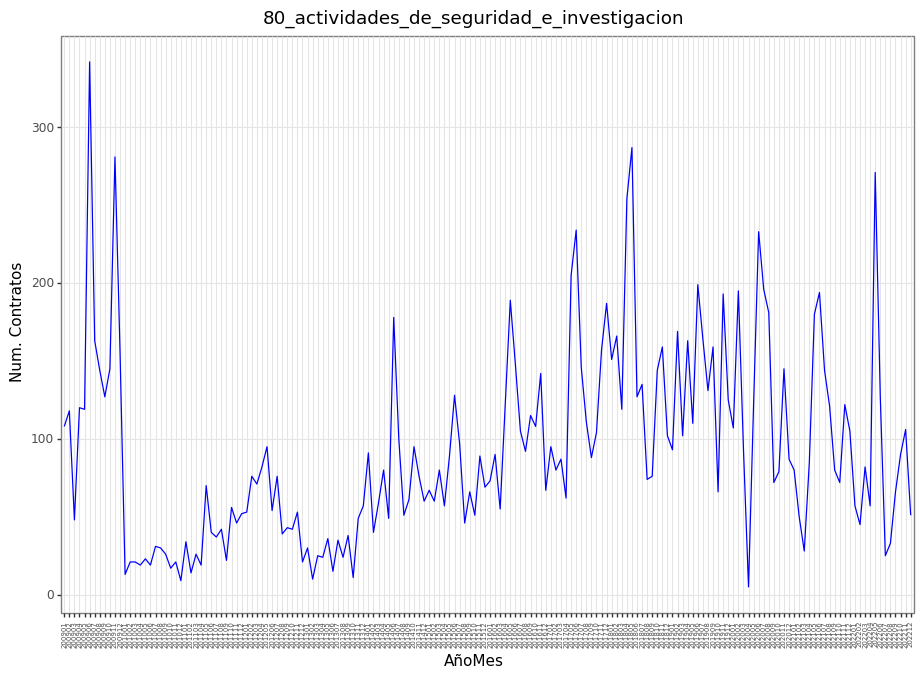

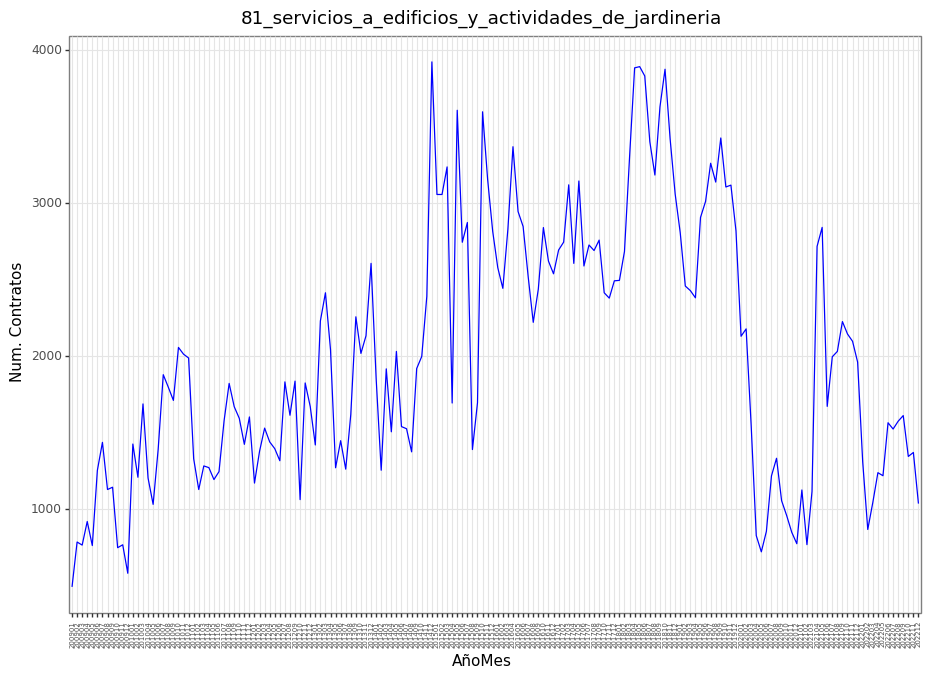

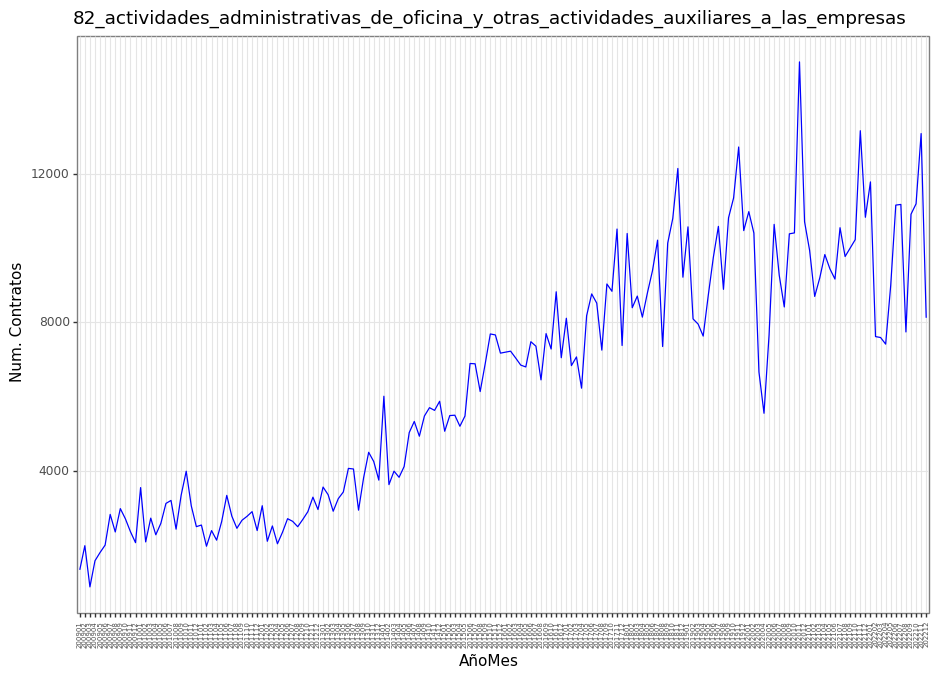

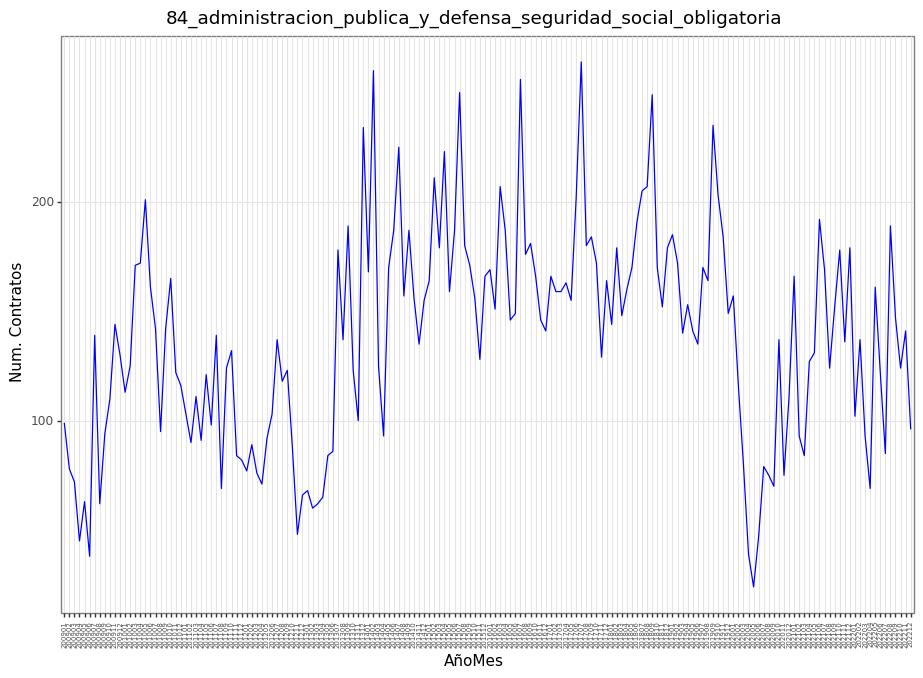

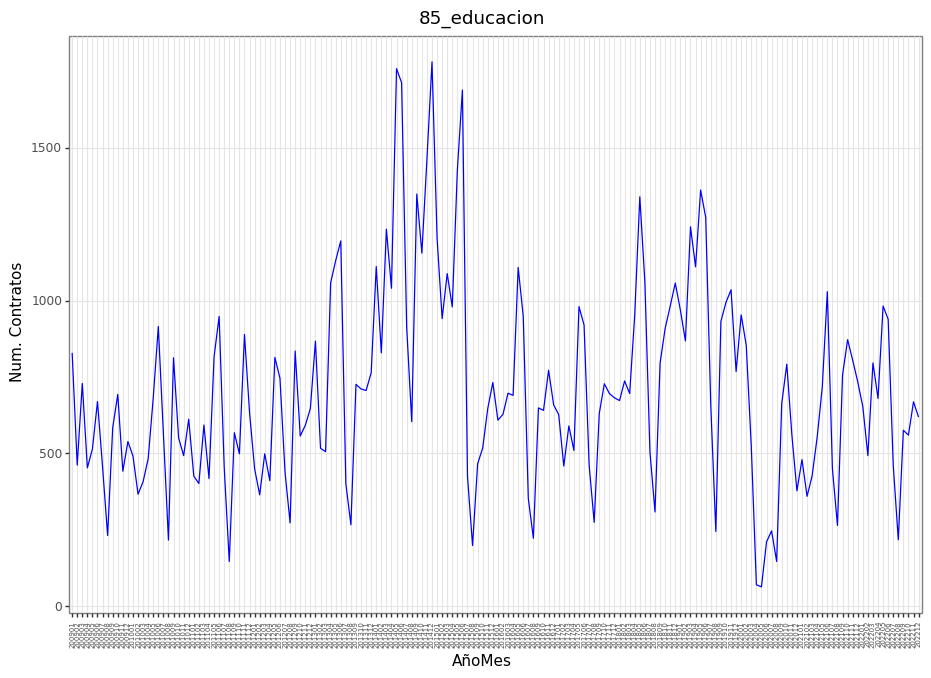

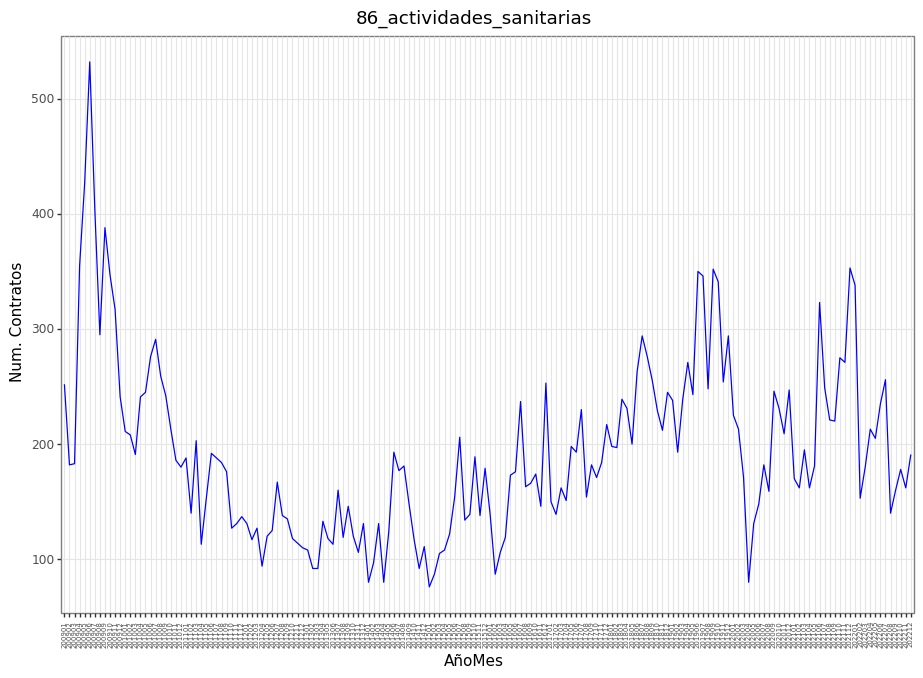

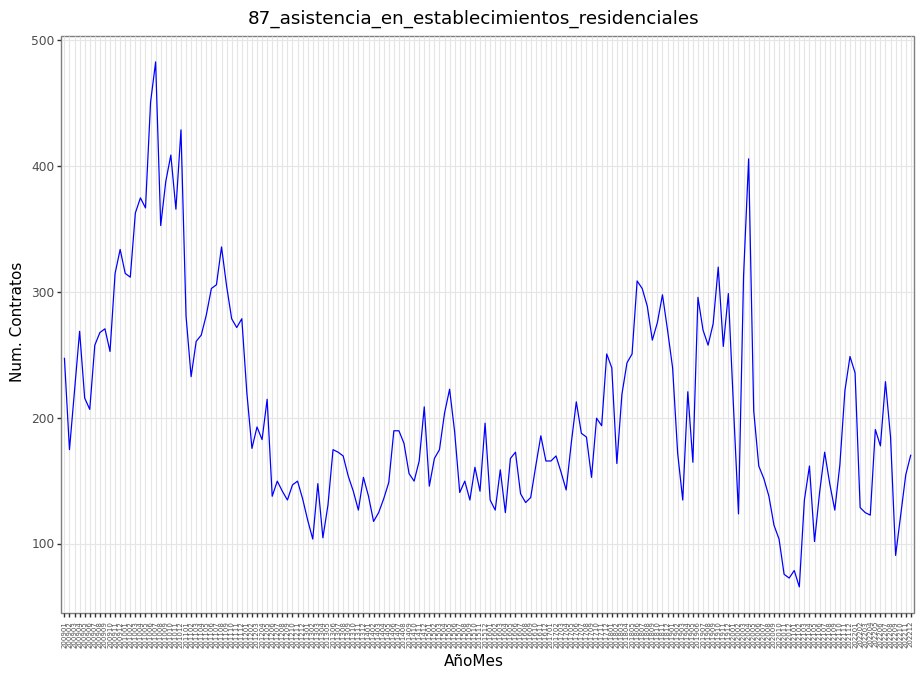

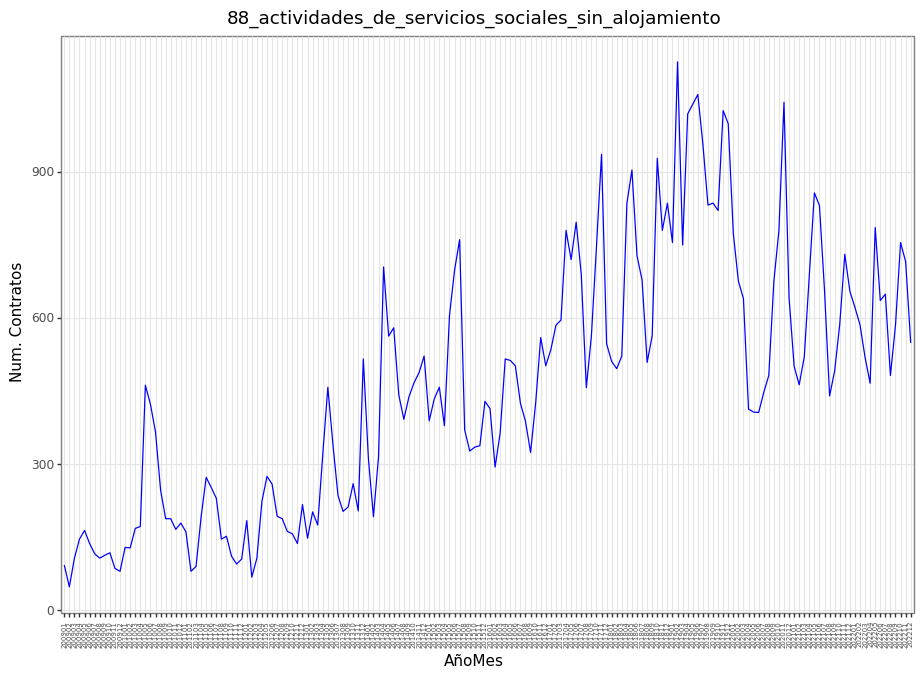

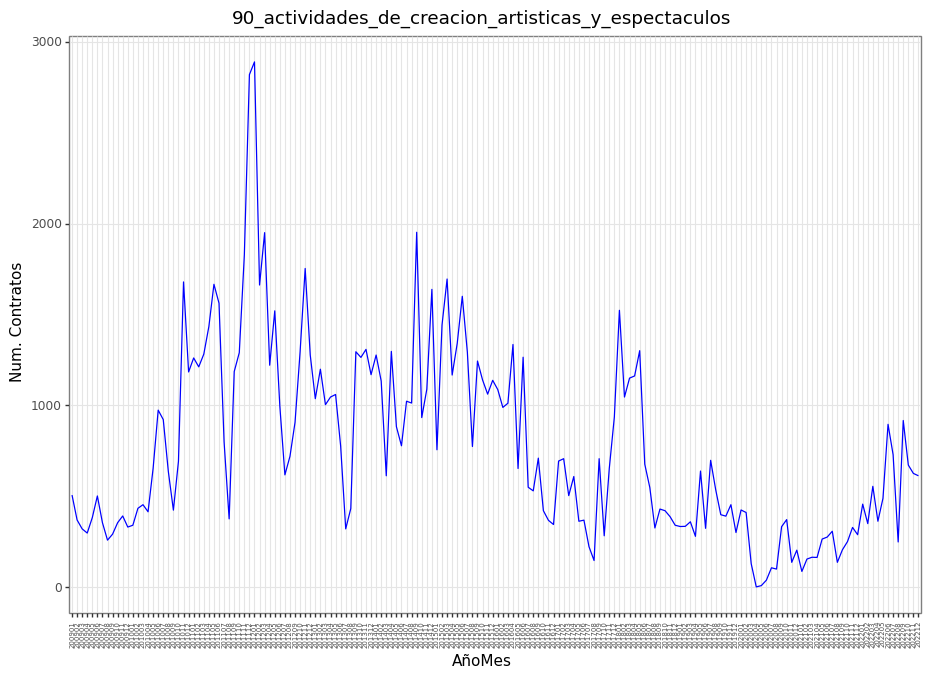

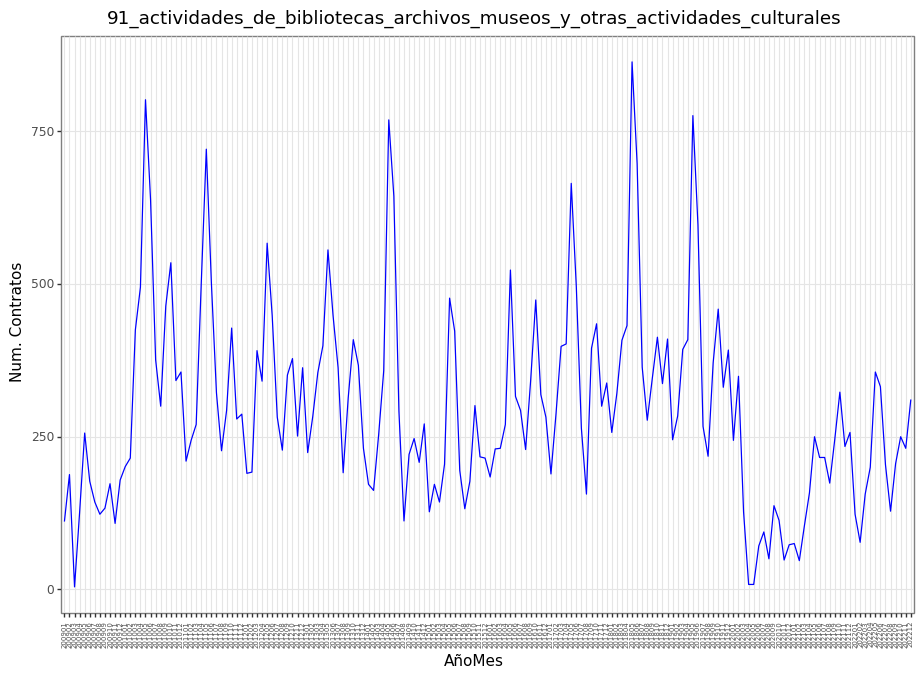

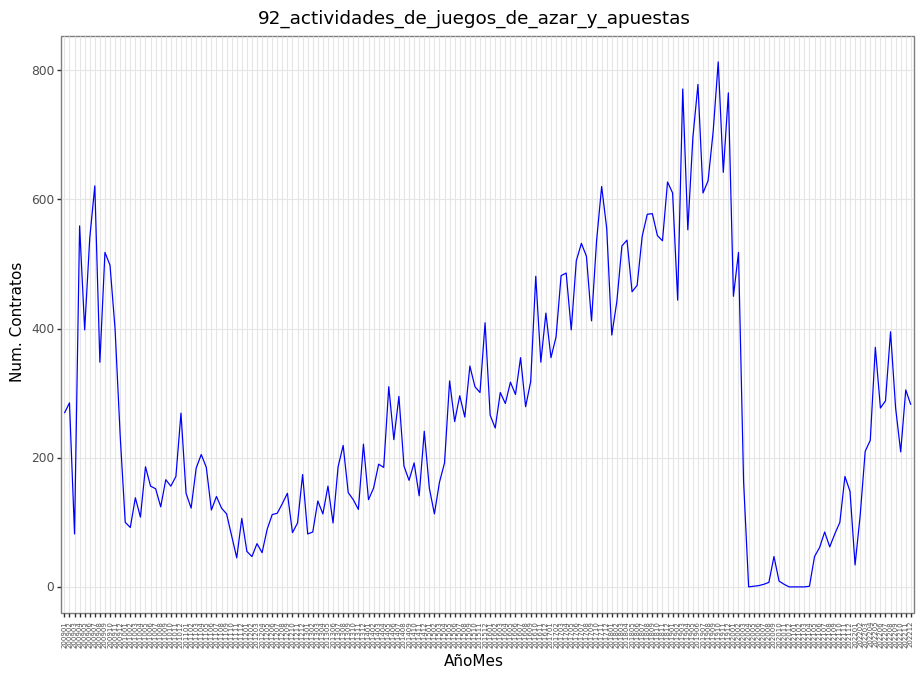

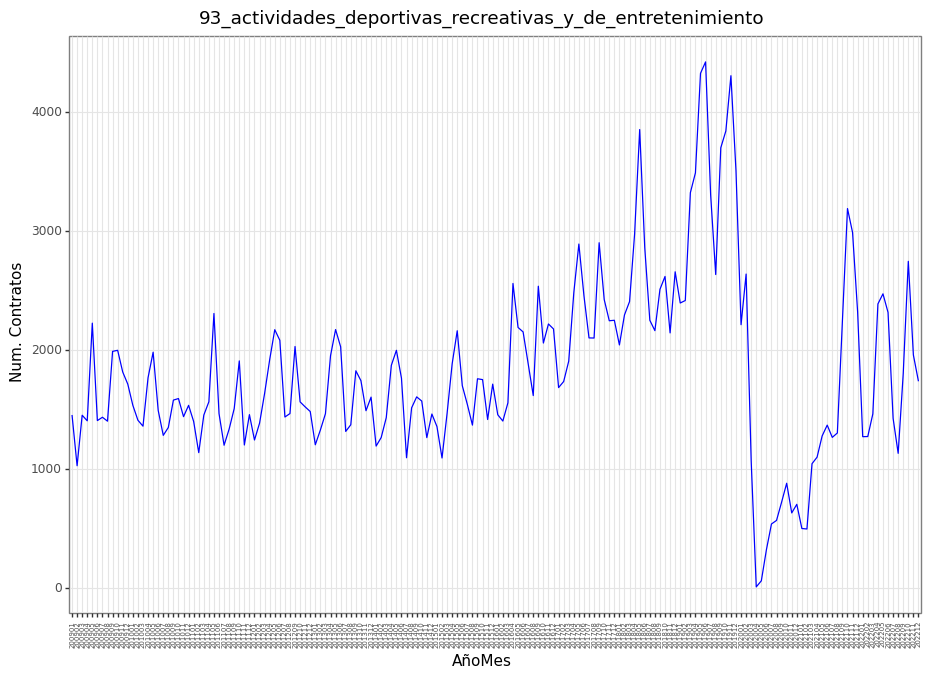

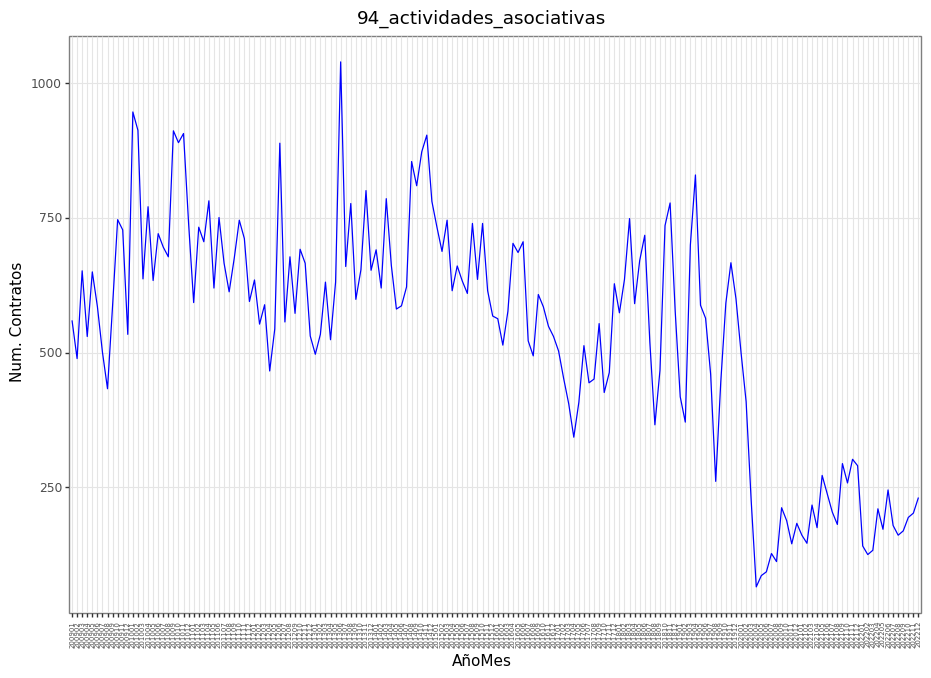

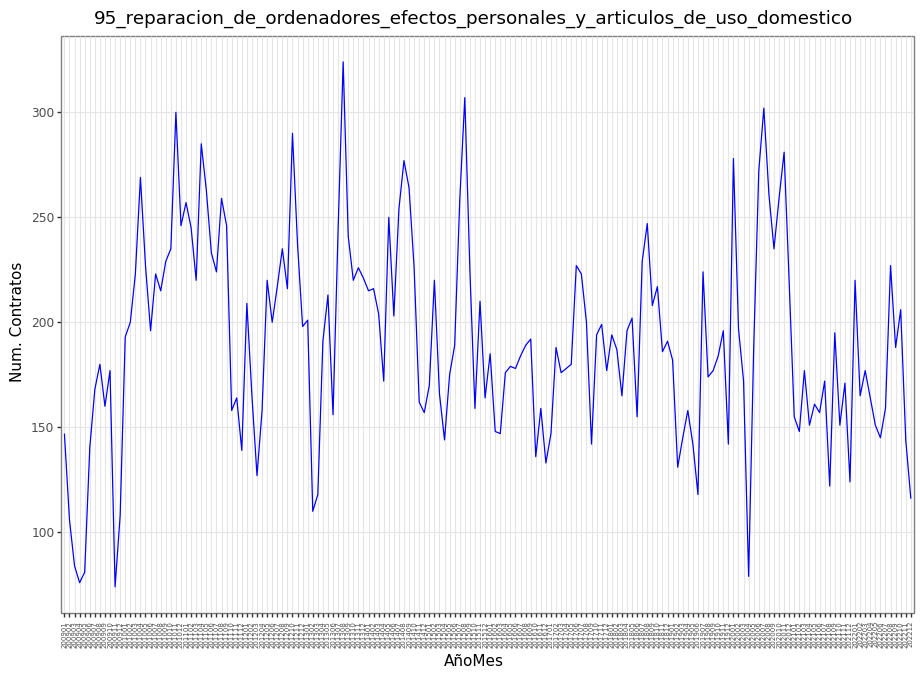

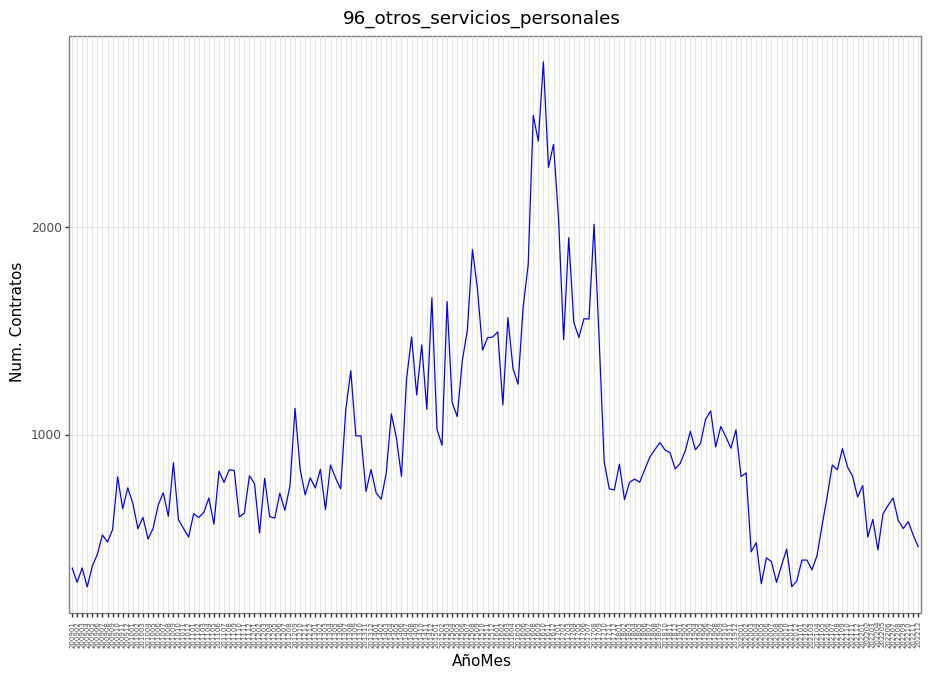

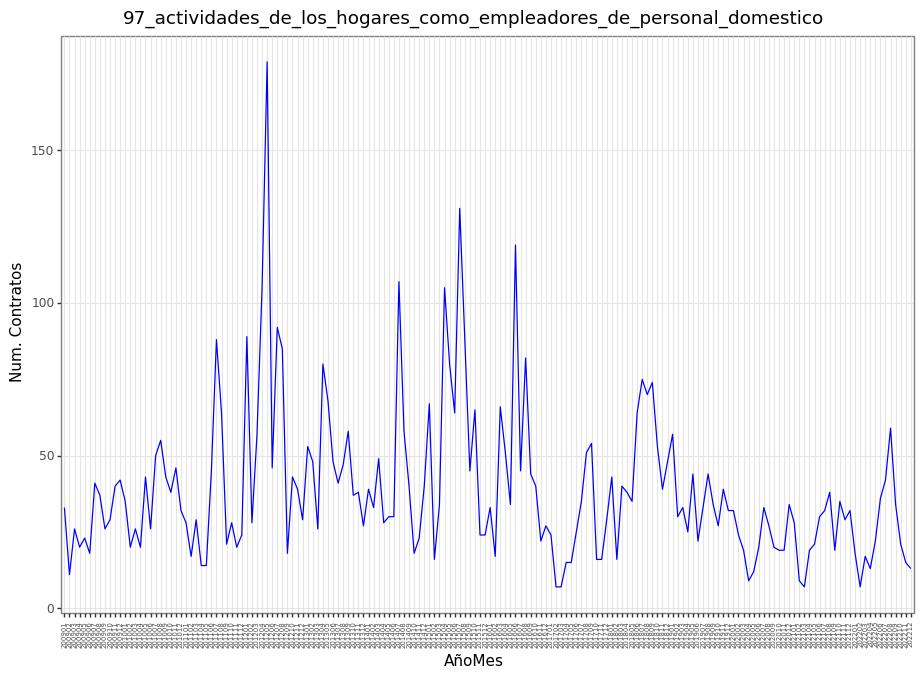

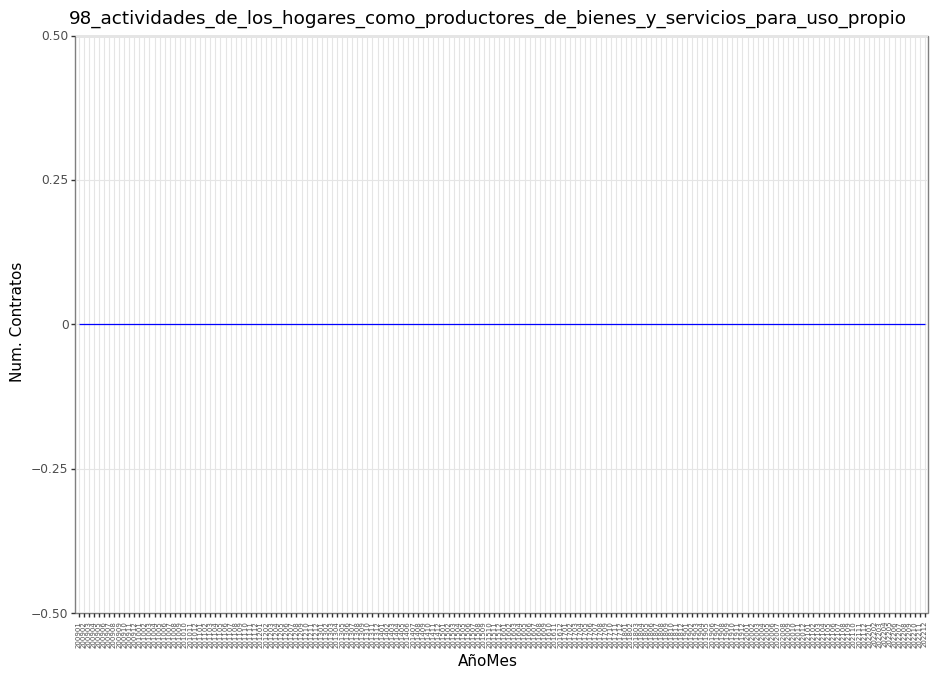

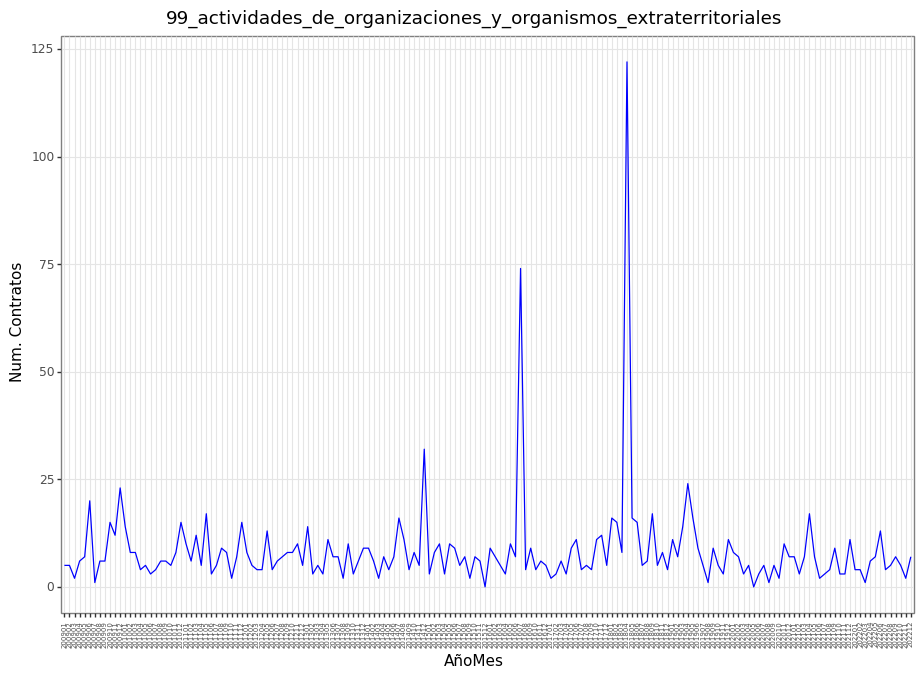

In [46]:
import plotnine 
plotnine.options.figure_size=(11, 7.5)

from plotnine import *

for i in range(len(tipos_val)):
    df_tmp = (
        datosmtlg
        >> filter(f.tipo == tipos_val[i])
        >> mutate(yearmoncat = as_factor(f.yearmon))
        >> arrange(f.yearmon)
    )
    p1 = (
        ggplot( df_tmp, aes(x = "yearmoncat", y = "count"))
        + geom_line(group = 1, color = "blue")
        + labs(
              title = tipos_val[i],
              x = "AñoMes",
              y = "Num. Contratos"
              )
        + theme_bw()
        + theme(
                panel_grid_minor=element_blank(),
                axis_text_x=element_text(angle = 90, hjust = 0.5, size = 5)
               ) 
    )
    print(p1)


+ Se podría continuar con el análisis para quedarse con aquellas series que mejor representen el sector industrial español.
    + Por ejemplo quedándome con aquellos CNAEs con mayor valor medio histórico o en los últimos 3 años. 
    + Así se puede evitar el representar todos los ~100 CNAEs que se han generado.
+ Igualmente, son series que se prestan perfectamente a crear una proyección a los siguientes meses vista.
    + Algunas de estas series, presentan patrones de estacionalidad y de tendencia muy claros.
    + En particular estas proyecciones a futuro, se podrían hacer con estas series de mayor volumen de contratos.

---